Paris case study

In this notebook, we focus **exclusively on Paris Airbnb listings**. We apply, compare, and interpret the core methods covered in the course:
1. **Exploratory analysis and Dimensionality reduction:** PCA (course content) and UMAP (extra method).
2. **Baseline classification models:** LDA and CART (Decision Trees).
3. **Ensemble methods:** Bootstrap, Bagging, and Random Forest.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore') 

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec 
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

from sklearn.utils import resample

from sklearn.decomposition import PCA
import umap.umap_ as umap # 'umap-learn' and not 'umap'

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.max_columns', None)

from sklearn.metrics import f1_score, roc_curve, auc
from sklearn.inspection import permutation_importance

FIG_DIR = Path("figures/1_ML_Paris")
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

def save_fig(name, fig=None):
    """Save the current figure (or `fig`) as figures/1_ML_Paris/<name>.png."""
    (fig or plt.gcf()).savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

Data loading and the common train/test split.

Every method below uses the same 24 features (the `pg_*` columns duplicate `rt_*`, as checked in the next section) and the same stratified 80/20 split (`random_state=42`), so all the test scores of the notebook are comparable.

In [2]:
DATA_PATH = "data/paris_dataset_final_ready.csv.gz"

df_paris = pd.read_csv(DATA_PATH, compression='gzip', low_memory=False)
print(f"{df_paris.shape[1]} columns.\n")

# pg_* duplicates rt_* (checked just below), so the listing type is encoded once, through rt_*
pg_cols = [c for c in df_paris.columns if c.startswith("pg_")]
y = df_paris['target_class']
X = df_paris.drop(columns=['target_class', 'price_clean', 'city_label'] + pg_cols)

# One split for every method (same random_state everywhere), so LDA, CART, bagging and RF share the same test set
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)   # stratify to preserve class distribution in both train and test sets

print(f"\nFeatures (X) : {X.shape[1]} columns")
print(f"Target (y) : {len(y)} values")
print(f"\nClass distribution:")
print(y.value_counts().sort_index())
print(f"Train dimensions: X={X_train.shape}, y={y_train.shape}")
print(f"Test dimensions:  X={X_test.shape}, y={y_test.shape}\n")

30 columns.


Features (X) : 24 columns
Target (y) : 73111 values

Class distribution:
target_class
0    19114
1    17449
2    18299
3    18249
Name: count, dtype: int64
Train dimensions: X=(58488, 24), y=(58488,)
Test dimensions:  X=(14623, 24), y=(14623,)



# PCA: Principal Component Analysis

### Removing redundancy in PCA and UMAP: motivations

rt_* and pg_* both describe the listing type (entire unit vs private room vs etc.). Thus, they encode the same information. Keeping both is like repeating the same feature twice.

We keep a single encoding of listing type to avoid double-counting the same information. This produces cleaner PCA/UMAP embeddings and more interpretable, more stable downstream models.


It harms PCA/UMAP interpretation:

- PCA: duplicated signals can dominate the first components and make PC1 “listing type” twice instead of revealing other structure (distance, size, amenities scores…).
- UMAP (distance-based): duplicated binary features can double-count that information, pulling points together/apart mainly because of repeated listing-type encoding.


It can hurt modeling (make it unstable): even if performance doesn’t crash, interpretation becomes messy. Removing redundancy gives cleaner embeddings (PCA/UMAP), more stable models, and a clearer interpretation not to duplicated categorical encoding.

In [3]:
X_redundancy = df_paris.drop(columns=["target_class", "price_clean", "city_label"], errors="ignore").copy()

rt_cols = [c for c in X_redundancy.columns if c.startswith("rt_")]
pg_cols = [c for c in X_redundancy.columns if c.startswith("pg_")]

corr = pd.DataFrame(index=rt_cols, columns=pg_cols)
for r in rt_cols:
    for p in pg_cols:
        corr.loc[r, p] = X_redundancy[r].corr(X_redundancy[p])

corr = corr.astype(float)
corr

,pg_entire_unit,pg_hotel,pg_private_room
rt_Entire home/apt,0.991545,-0.493997,-0.825274
rt_Private room,-0.927514,0.346177,0.882248
rt_Shared room,-0.156780,0.010979,-0.012236


The two encodings are strongly correlated: 0.99 between `rt_Entire home/apt` and `pg_entire_unit`, 0.88 between `rt_Private room` and `pg_private_room`. We keep `rt_*` only.

## Case A: Standardizing everything 

We standardize everything, including 0/1 variables. It corresponds roughly to doing PCA on a correlation matrix (each variable gets comparable scale).

Scaling 0/1 variables to unit variance can make them very influential, especially if the feature is rare (very imbalanced 0/1) or if there exists several correlated binaries (rt_* and pg_* encode similar info).

It answers the question: “what variables matter equally?”.

In [4]:
warnings.filterwarnings('ignore')

#configuration
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.max_columns', None)


print(f" dataset loaded: {df_paris.shape}")
print(f"\n columns overview:")
print(df_paris.columns.tolist())

#check target
if 'target_class' in df_paris.columns:
    print(f"\n target found: {df_paris['target_class'].nunique()} classes")
    print(df_paris['target_class'].value_counts().sort_index())
else:
    print(" warning: 'target_class' not found in dataset")

#overview
print(f"\n first 5 rows:")
print(df_paris.head())

#prepare X/y and train/test split

#code
print("=" * 60)
print("preparation: X/y split and train/test split")
print("=" * 60)

#split X (features) and y (target)
y = df_paris['target_class']
X = df_paris.drop(columns=["target_class", "price_clean", "city_label"], errors="ignore").copy()

pg_cols = [c for c in X.columns if c.startswith("pg_")] # Drop redundant family: pg_*
X = X.drop(columns=pg_cols)

print("Dropped pg_* columns:", pg_cols)
print("New X shape:", X.shape)

#remove city_label if present
if 'city_label' in X.columns:
    X = X.drop(columns=['city_label'])

print(f"\nfeatures (X): {X.shape[1]} columns")
print(f"target (y): {len(y)} values")
print(f"\ndistribution of classes:")
print(y.value_counts().sort_index())

#stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    stratify=y, 
    random_state=42
)

print(f"\n split done:")
print(f"  train: {X_train.shape}")
print(f"  test : {X_test.shape}")
print(f"\ndistribution train:")
print(y_train.value_counts().sort_index())
print(f"\ndistribution test:")
print(y_test.value_counts().sort_index())

print([c for c in X.columns if c.startswith("rt_")])
print([c for c in X.columns if c.startswith("pg_")]) #should be empty after drop

 dataset loaded: (73111, 30)

 columns overview:
['accommodates', 'bedrooms', 'beds', 'minimum_nights_avg_ntm', 'number_of_reviews', 'price_clean', 'dist_to_center', 'bathrooms_qty', 'has_ac', 'has_elevator', 'has_dishwasher', 'has_parking', 'has_balcony', 'has_washing_machine', 'standing_thermal', 'score_chef_kitchen', 'score_coffee', 'score_wellness', 'score_work', 'score_view', 'score_secure', 'neigh_popularity', 'pg_entire_unit', 'pg_hotel', 'pg_private_room', 'rt_Entire home/apt', 'rt_Private room', 'rt_Shared room', 'city_label', 'target_class']

 target found: 4 classes
target_class
0    19114
1    17449
2    18299
3    18249
Name: count, dtype: int64

 first 5 rows:
   accommodates  bedrooms  beds  minimum_nights_avg_ntm  number_of_reviews  \
0             2       1.0   0.0                     2.0                  4   
1             1       1.0   1.0                    30.0                 42   
2             2       0.0   1.0                     1.0                403   
3    

PCA summarises the 24 features with uncorrelated linear combinations, ordered by the share of variance they explain. Two results stand out below:
- the variance is spread out: PC1 explains 16.2%, PC2 9.9%, and 17 components are needed to reach 90%. No single factor dominates the data;
- PC1 is a **size and equipment** axis (accommodates, bedrooms, beds, kitchen score, dishwasher). The **listing type** (entire home vs private room) only comes second, on PC2, together with air-conditioning.


PCA results
components for 90% variance: 17/24
components for 95% variance: 19/24
possible reduction: 20.8%


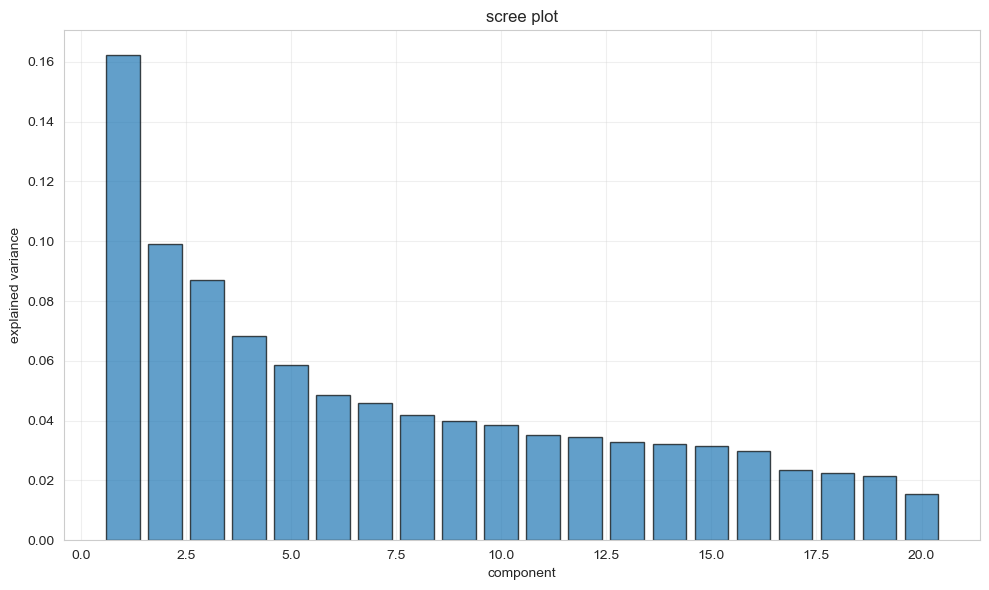

In [5]:
#standardization
scaler_pca = StandardScaler()
X_train_std = scaler_pca.fit_transform(X_train)
X_test_std = scaler_pca.transform(X_test)

#pca
pca_full = PCA()
pca_full.fit(X_train_std)

#explained variance
var_exp = pca_full.explained_variance_ratio_
var_cum = np.cumsum(var_exp)

#number of components
n_comp_95 = np.argmax(var_cum >= 0.95) + 1
n_comp_90 = np.argmax(var_cum >= 0.90) + 1

print(f"\nPCA results")
print(f"components for 90% variance: {n_comp_90}/{X.shape[1]}")
print(f"components for 95% variance: {n_comp_95}/{X.shape[1]}")
print(f"possible reduction: {(1 - n_comp_95/X.shape[1])*100:.1f}%")

#screeplot
plt.figure(figsize=(10, 6))
plt.bar(range(1, min(21, len(var_exp)+1)), var_exp[:20], alpha=0.7, edgecolor='black')
plt.title("scree plot")
plt.xlabel("component")
plt.ylabel("explained variance")
plt.grid(alpha=0.3)
plt.tight_layout()
save_fig("pca_A_01_scree")
plt.show()

This scree plot displays the explained variance for the first 20 components of the PCA performed on the standardized Paris dataset. 

PC1 explains 16.2% and PC2 explains 9.9% Then, it gradually decreases (no huge “elbow”). Our data has no single dominant factor: variance is spread across many features (normal for mixed “size + amenities + scores + location + binaries”).

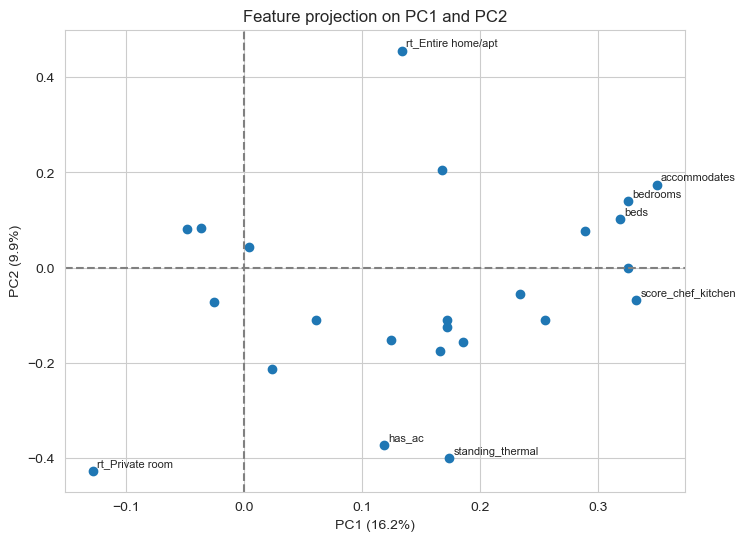

In [6]:
#plot features projection (loadings) on PC1 and PC2 axes, labelling the 8 features furthest from the origin
load_2d = pca_full.components_[:2].T
plt.figure(figsize=(8,6))
plt.scatter(load_2d[:, 0], load_2d[:, 1])
for i in np.argsort(np.linalg.norm(load_2d, axis=1))[-8:]:
    plt.annotate(X.columns[i], load_2d[i], fontsize=8, xytext=(3, 3), textcoords='offset points')
plt.axhline(0, color='grey', linestyle='--')
plt.axvline(0, color='grey', linestyle='--')
pc1_pct = pca_full.explained_variance_ratio_[0]*100
pc2_pct = pca_full.explained_variance_ratio_[1]*100
plt.xlabel(f'PC1 ({pc1_pct:.1f}%)')
plt.ylabel(f'PC2 ({pc2_pct:.1f}%)')
plt.title('Feature projection on PC1 and PC2')
save_fig("pca_A_02_loadings")
plt.show()

We are plotting each feature by its loading on:
- x = loading on PC1
- y = loading on PC2

How to interpret it?
- Points far from (0,0) = features that matter a lot for PC1/PC2.
- Same direction = positively correlated structure in this 2D PC space.
- Opposite direction = trade-off / negative relationship.

PC1 is mainly "size" (accommodates, bedrooms, beds, bathrooms_qty) + "equipment" (has_dishwasher, score_chef_kitchen, score_coffee, score_wellness).

--> PC1 = "bigger + better-equipped listings".

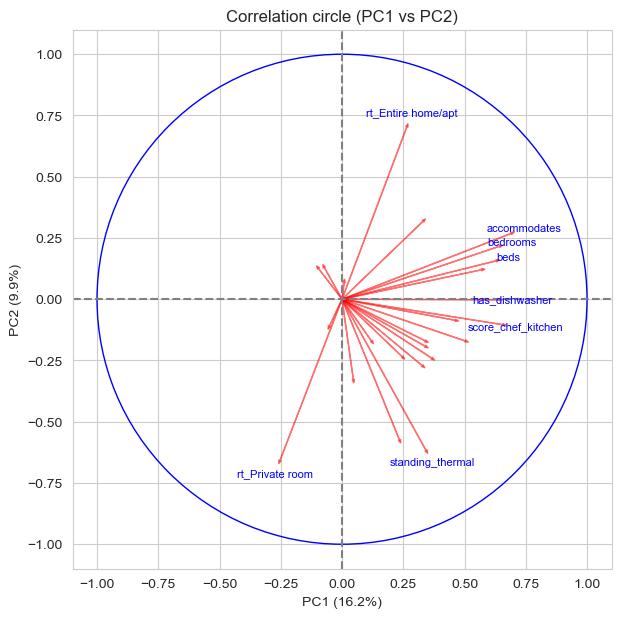

In [7]:
#correlation circle for PC1 and PC2: correlation between each standardised feature and the PC scores,
# i.e. loading x sqrt(eigenvalue). An arrow close to the circle means the feature is well represented by PC1-PC2.
corrs_2d = pca_full.components_[:2].T * np.sqrt(pca_full.explained_variance_[:2])
plt.figure(figsize=(7,7))
plt.axhline(0, color='grey', linestyle='--')
plt.axvline(0, color='grey', linestyle='--')
plt.gca().add_artist(plt.Circle((0,0), 1, color='b', fill=False))
for i in range(len(X.columns)):
    plt.arrow(0, 0, corrs_2d[i,0], corrs_2d[i,1], color='r', alpha=0.5, head_width=0.01)
top_idx = np.argsort(np.linalg.norm(corrs_2d, axis=1))[-8:] #8 features best represented by PC1/PC2
for i in top_idx:
    plt.text(corrs_2d[i,0]*1.08, corrs_2d[i,1]*1.08, X.columns[i], fontsize=8, ha='center', va='center', color='blue')
plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.1)
plt.xlabel(f'PC1 ({pc1_pct:.1f}%)')
plt.ylabel(f'PC2 ({pc2_pct:.1f}%)')
plt.title('Correlation circle (PC1 vs PC2)')
plt.gca().set_aspect('equal')
save_fig("pca_A_03_correlation_circle")
plt.show()

How to read it?
- Each arrow gives the correlation of a feature with PC1 (x) and PC2 (y). The closer to the circle, the better the feature is represented by the PC1–PC2 plane.
- Angle between arrows: a small angle means positively correlated; opposite directions mean negatively correlated; ~90° means weakly related in this PC1/PC2 view.

Interpretation:
- Size and equipment point to the right: accommodates, bedrooms, beds, has_dishwasher and score_chef_kitchen all correlate around 0.6–0.7 with PC1.
- `rt_Entire home/apt` points up (0.70 with PC2) and `rt_Private room` down (−0.66): PC2 opposes entire homes to private rooms.
- `has_ac` and `standing_thermal` also point down (about −0.6 with PC2), on the same side as private rooms. This only means they load on PC2 with the same sign: air-conditioning and private rooms are barely correlated with each other (0.09).

No arrow reaches the circle: PC1–PC2 only hold 26% of the variance, so each feature is only partly represented in this plane.

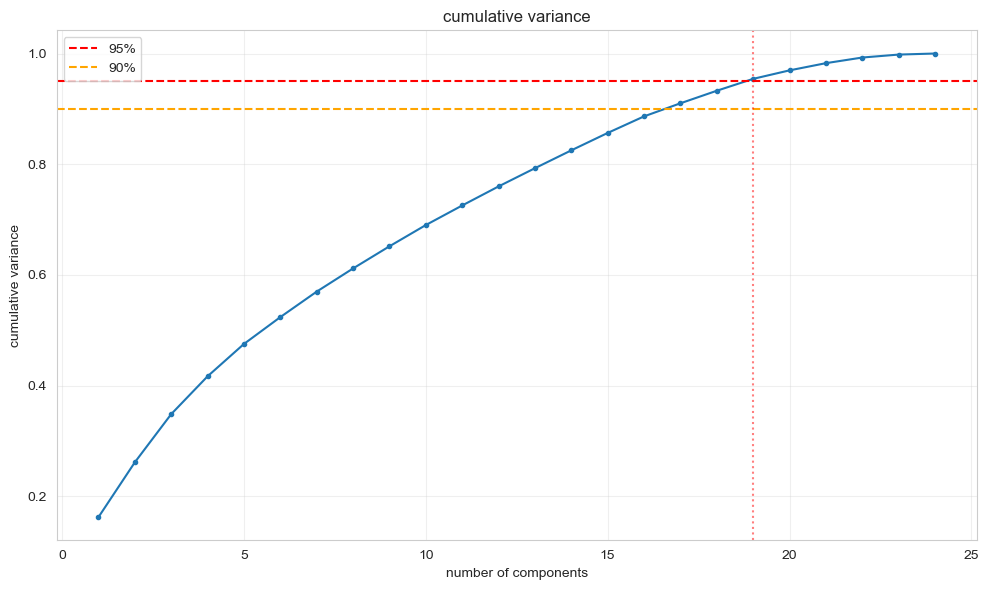

In [8]:
#cumulative variance
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(var_cum)+1), var_cum, marker='o', markersize=3)
plt.axhline(y=0.95, color='r', linestyle='--', label='95%')
plt.axhline(y=0.90, color='orange', linestyle='--', label='90%')
plt.axvline(x=n_comp_95, color='r', linestyle=':', alpha=0.5)
plt.title("cumulative variance")
plt.xlabel("number of components")
plt.ylabel("cumulative variance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
save_fig("pca_A_04_cumulative_variance")
plt.show()

90% variance: 17 components out of 24; 95% variance: 19 components out of 24
“Possible reduction” 20.8%

If we want to keep almost all information, PCA doesn’t give a huge reduction (we still need many PCs).

For visualization, using 2 PCs is still fine — but PC1 + PC2 are only 26.1% of total variance.

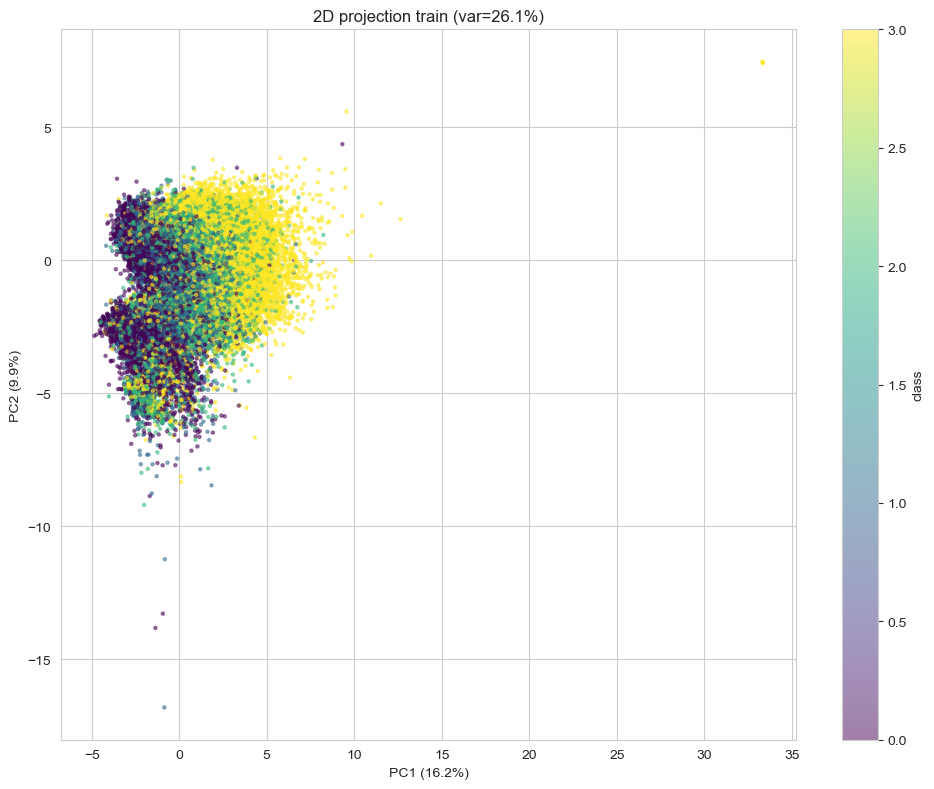


 top 10 features PC1:
accommodates          0.349
score_chef_kitchen    0.332
bedrooms              0.325
has_dishwasher        0.325
beds                  0.319
bathrooms_qty         0.289
score_coffee          0.254
score_wellness        0.234
has_elevator          0.186
standing_thermal      0.174

 top 10 features PC2:
rt_Entire home/apt     0.456
rt_Private room       -0.426
standing_thermal      -0.400
has_ac                -0.372
number_of_reviews     -0.212
has_washing_machine    0.206
has_parking           -0.176
accommodates           0.174
has_elevator          -0.156
score_view            -0.152


In [9]:
#2D projection
pca_2d = PCA(n_components=2)
X_train_pca_2d = pca_2d.fit_transform(X_train_std)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_train_pca_2d[:, 0], X_train_pca_2d[:, 1], 
                     c=y_train, cmap='viridis', s=5, alpha=0.5)
plt.title(f"2D projection train (var={pca_2d.explained_variance_ratio_.sum():.1%})")
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]:.1%})")
plt.colorbar(scatter, label='class')
plt.tight_layout()
save_fig("pca_A_05_projection_by_class")
plt.show()

#signed loadings, sorted by absolute value
for k in range(2):
    loadings = pd.Series(pca_full.components_[k], index=X.columns)
    print(f"\n top 10 features PC{k+1}:")
    print(loadings.reindex(loadings.abs().sort_values(ascending=False).index).head(10).round(3).to_string())

Clear gradient along PC1:
- higher classes (more expensive quartiles) tend to sit more to the right
- Classes overlap a lot (expected), because: PC1+PC2 explains only 26% of variance and price quartile is influenced by multiple factors, some nonlinear.

Interpretation:

- PC1 is strongly aligned with price even though we removed price_clean. It's normal: size + amenities quality are real drivers of price.

- The isolated point at PC1 ≈ 33 is not a luxury flat but a data anomaly. It is a group of listings declared as "private room" with 30 bedrooms, 30 beds and 30 bathrooms for 16 guests — whole buildings (hostels, hotels) described at building level. 90 listings even have more bedrooms than guests (up to 38 bedrooms for 2 guests).

## Case B: Separating scaling 

We should separate scaling whenever we want to see structure driven more by continuous attributes (distance, accommodates, amenities scores…) rather than “room type". 

We will use the same PCA but scaling continuous features and leave binary features as 0/1. This automatically “downweights” binaries a bit (because their variance is ≤ 0.25), and can reveal other structure.

It answers the question. : “what structure exists beyond room type?”.

In [10]:
# y = target
y = df_paris["target_class"].copy()

# X = features (remove target and leakage-like columns)
X = df_paris.drop(columns=["target_class", "price_clean", "city_label"], errors="ignore").copy()

pg_cols = [c for c in X.columns if c.startswith("pg_")] # Drop redundant family: pg_*
X = X.drop(columns=pg_cols)

print("X shape:", X.shape)
print("y distribution:\n", y.value_counts())

print([c for c in X.columns if c.startswith("rt_")])
print([c for c in X.columns if c.startswith("pg_")]) #should be empty after drop



#  Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Identify binary vs continuous columns:
#    - binary: values are subset of {0,1} (or only {0} or {1})
#    - continuous: everything else
def is_binary_series(s: pd.Series) -> bool:
    vals = pd.Series(s.dropna().unique())     # Drop NA, get unique values
    if len(vals) == 0:
        return False
    try:     # Try to coerce to numeric when possible
        vals = pd.to_numeric(vals)
    except Exception:
        return False
    return set(vals.tolist()).issubset({0, 1})     # Check subset of {0,1}


binary_cols = [c for c in X_train.columns if is_binary_series(X_train[c])]
continuous_cols = [c for c in X_train.columns if c not in binary_cols]

print(f"Detected {len(continuous_cols)} continuous columns:", continuous_cols)
print(f"Detected {len(binary_cols)} binary columns:", binary_cols)

# Scale continuous features (fit on train, transform both) and Keep binary as it is.
scaler = StandardScaler()

X_train_cont_scaled = scaler.fit_transform(X_train[continuous_cols])
X_test_cont_scaled  = scaler.transform(X_test[continuous_cols])

# Convert back to DataFrame for clean concatenation
X_train_cont_scaled = pd.DataFrame(X_train_cont_scaled, columns=continuous_cols, index=X_train.index)
X_test_cont_scaled  = pd.DataFrame(X_test_cont_scaled,  columns=continuous_cols, index=X_test.index)

# Binary stays as 0/1 (ensure numeric dtype)
X_train_bin = X_train[binary_cols].astype(float)
X_test_bin  = X_test[binary_cols].astype(float)

# Rebuild final matrices in the same column order as original X
X_train_prepared = pd.concat([X_train_cont_scaled, X_train_bin], axis=1)[X.columns]
X_test_prepared  = pd.concat([X_test_cont_scaled,  X_test_bin],  axis=1)[X.columns]

print("Prepared train shape:", X_train_prepared.shape)
print("Prepared test shape:", X_test_prepared.shape)

X shape: (73111, 24)
y distribution:
 target_class
0    19114
2    18299
3    18249
1    17449
Name: count, dtype: int64
['rt_Entire home/apt', 'rt_Private room', 'rt_Shared room']
[]
Detected 15 continuous columns: ['accommodates', 'bedrooms', 'beds', 'minimum_nights_avg_ntm', 'number_of_reviews', 'dist_to_center', 'bathrooms_qty', 'standing_thermal', 'score_chef_kitchen', 'score_coffee', 'score_wellness', 'score_work', 'score_view', 'score_secure', 'neigh_popularity']
Detected 9 binary columns: ['has_ac', 'has_elevator', 'has_dishwasher', 'has_parking', 'has_balcony', 'has_washing_machine', 'rt_Entire home/apt', 'rt_Private room', 'rt_Shared room']
Prepared train shape: (58488, 24)
Prepared test shape: (14623, 24)



PCA results (scale continuous only)
components for 90% variance: 13/24
components for 95% variance: 16/24
possible reduction: 33.3%


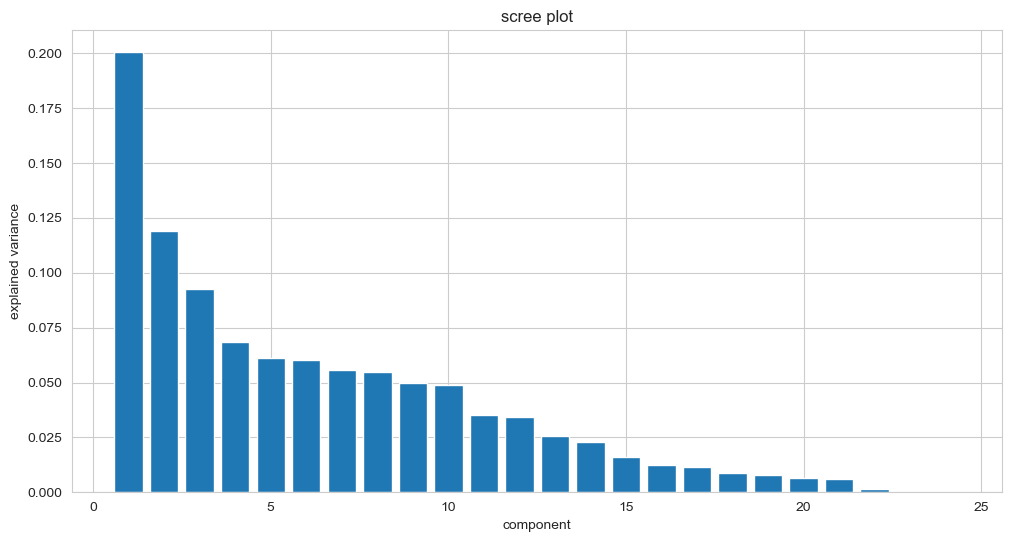

In [11]:
#PCA 
pca_full = PCA()
pca_full.fit(X_train_prepared)

explained_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

n90 = np.argmax(cum_var >= 0.90) + 1
n95 = np.argmax(cum_var >= 0.95) + 1

print("\nPCA results (scale continuous only)")
print(f"components for 90% variance: {n90}/{X.shape[1]}")
print(f"components for 95% variance: {n95}/{X.shape[1]}")
print(f"possible reduction: {(1 - n95 / X.shape[1]) * 100:.1f}%")

# Scree plot
plt.figure()
plt.bar(range(1, len(explained_var) + 1), explained_var)
plt.title("scree plot")
plt.xlabel("component")
plt.ylabel("explained variance")
save_fig("pca_B_01_scree")
plt.show()

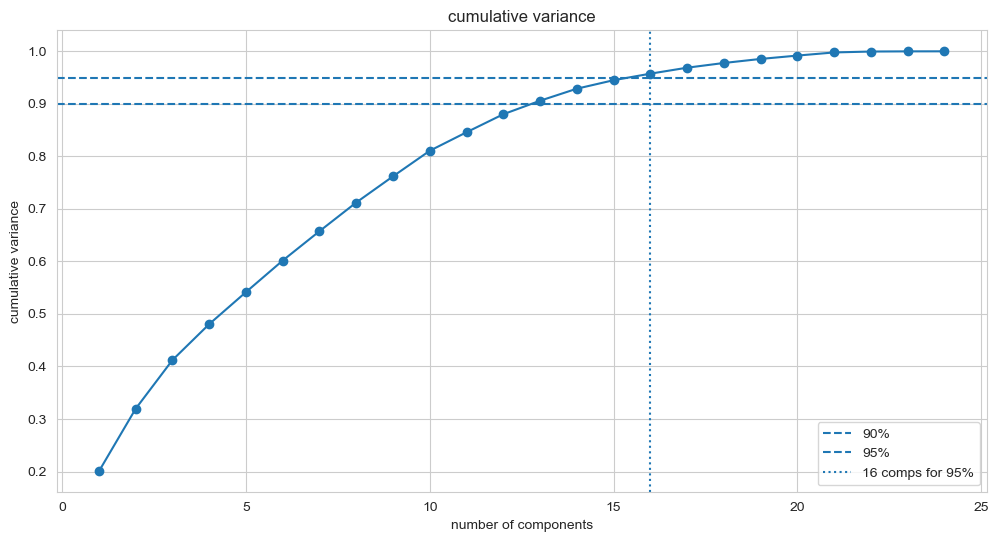

In [12]:
# Cumulative variance plot
plt.figure()
plt.plot(range(1, len(cum_var) + 1), cum_var, marker="o")
plt.axhline(0.90, linestyle="--", label="90%")
plt.axhline(0.95, linestyle="--", label="95%")
plt.axvline(n95, linestyle=":", label=f"{n95} comps for 95%")
plt.title("cumulative variance")
plt.xlabel("number of components")
plt.ylabel("cumulative variance")
plt.legend()
save_fig("pca_B_02_cumulative_variance")
plt.show()

We need fewer components: 
- 90%: 13 vs before 17
- 95%: 16 vs before 19

It is expected. 
- Before, we standardized everything: each variable contributes as 1 unit of variance. So, total variance = number of variables (24). 
- Now, continuous variables still have variance = 1 (because scaled), but binary variables keep their natural variance (≈ p(1−p), often < 0.25, sometimes much smaller if rare). Therefore, binaries contribute less to total variance, and the remaining variance is “more concentrated”, so we hit 90/95% with fewer PCs.

PCA focuses more on the continuous structure (size, distance, scores), and less on “binary noise / redundancy”.

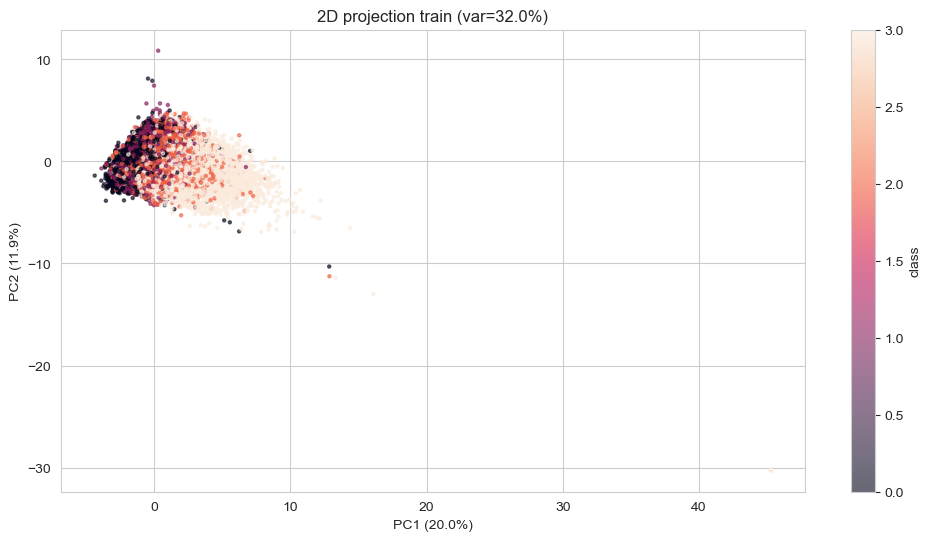

In [13]:
# 2D projection (PC1, PC2) with class color
pca_2d = PCA(n_components=2)
Z_train_2d = pca_2d.fit_transform(X_train_prepared)

plt.figure()
sc = plt.scatter(Z_train_2d[:, 0], Z_train_2d[:, 1], c=y_train, s=5, alpha=0.6)
plt.title(f"2D projection train (var={pca_2d.explained_variance_ratio_.sum()*100:.1f}%)")
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)")
plt.colorbar(sc, label="class")
save_fig("pca_B_03_projection_by_class")
plt.show()

In [14]:
# Top 10 features for PC1 and PC2 (signed loadings, sorted by absolute value)
for k in range(2):
    loadings = pd.Series(pca_full.components_[k], index=X.columns)
    top10 = loadings.reindex(loadings.abs().sort_values(ascending=False).index).head(10)
    print(f"\nTop 10 features PC{k+1} (abs loading):")
    print(top10.round(3).to_string())


Top 10 features PC1 (abs loading):
accommodates          0.437
bedrooms              0.423
beds                  0.409
bathrooms_qty         0.378
score_chef_kitchen    0.296
score_wellness        0.245
score_coffee          0.232
score_work            0.184
standing_thermal      0.169
has_dishwasher        0.137

Top 10 features PC2 (abs loading):
score_coffee          0.432
score_chef_kitchen    0.415
bedrooms             -0.315
score_view            0.269
accommodates         -0.262
standing_thermal      0.256
score_secure          0.248
bathrooms_qty        -0.242
score_work            0.226
beds                 -0.218


With continuous features scaled and binaries kept as 0/1, PC1 and PC2 hold 32% of the variance (20.0% + 11.9%), against 26% in case A.
- **PC1 is a pure size axis**: accommodates (0.44), bedrooms (0.42), beds (0.41), bathrooms (0.38), then the equipment scores.
- **PC2 opposes equipment to size**: coffee and kitchen scores, view, thermal comfort, self check-in (+) against bedrooms, accommodates, bathrooms (−). At a given size, it separates well-equipped listings from bare ones.
- The listing-type binaries, which drove PC2 in case A, have left the top loadings: with their natural variance (≤ 0.25) they weigh little.

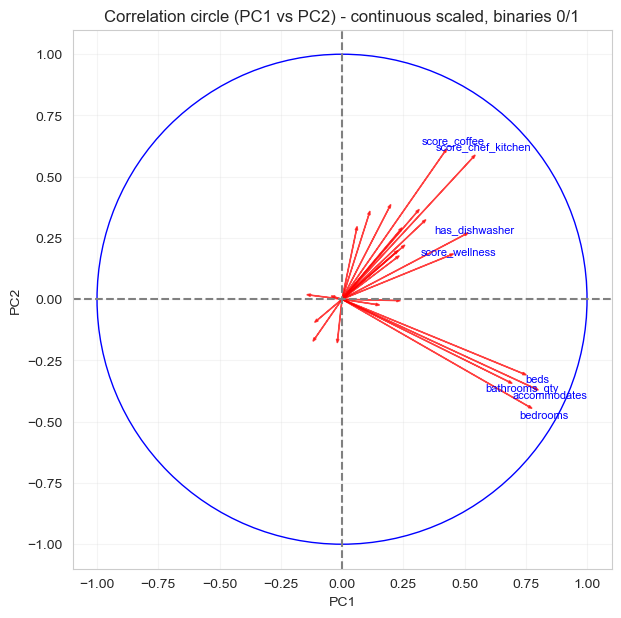

In [15]:
# Correlation circle (PC1 vs PC2). With mixed scaling the loadings are no longer correlations,
# so the correlation between each feature and the PC scores is computed directly.
scores_2d = pca_full.transform(X_train_prepared)[:, :2]
corrs_2d = np.array([[np.corrcoef(X_train_prepared[c], scores_2d[:, k])[0, 1] for k in range(2)] for c in X.columns])

plt.figure(figsize=(7, 7))
plt.axhline(0, linestyle="--", color="grey")
plt.axvline(0, linestyle="--", color="grey")
plt.gca().add_artist(plt.Circle((0, 0), 1, color="b", fill=False))
plt.title("Correlation circle (PC1 vs PC2) - continuous scaled, binaries 0/1")

for i, col in enumerate(X.columns):
    plt.arrow(0, 0, corrs_2d[i, 0], corrs_2d[i, 1], head_width=0.01, alpha=0.7, color="red")
for i in np.argsort(np.linalg.norm(corrs_2d, axis=1))[-8:]:
    plt.text(corrs_2d[i, 0]*1.08, corrs_2d[i, 1]*1.08, X.columns[i], fontsize=8, ha="center", va="center", color="blue")

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.1)
plt.gca().set_aspect("equal")
plt.grid(True, alpha=0.2)
save_fig("pca_B_04_correlation_circle")
plt.show()

# UMAP : Uniform Manifold Approximation

We will ask and answer the following questions: 
- What is UMAP?
- Is a train/test separation necessary?
- On which variables shall we focus?
- PCA vs UMAP: what are the differences?

## What is UMAP ?
UMAP is a non-linear dimensionality reduction method designed to preserve structure of a dataset viewed as lying on a manifold. UMAP’s practical aim is producing an embedding useful for visualization (competitive with t‑SNE but often faster and more scalable).

It is an appropriate exploratory tool here because it can reveal non-linear local structure (listing “archetypes” and neighborhood relationships). UMAP is best interpreted as neighborhood structure (who is close to whom) not as interpretable axes or exact inter-cluster distances.
It is most reliable for statements about local neighborhoods. If two points are close in the UMAP embedding, they should look close in the original feature space.

UMAP is not reliable for axis or distance interpretations: 
- Axes are not interpretable because UMAP coordinates are not tied to linear combinations of original
features and can rotate without changing the solution quality.
- Distances between separated clusters can be visually meaningful, but should not be treated as
precise “how far apart segments are” in the original high-dimensional space

### The importance of the parameters : 
- n_neighbors (local vs global trade-off): it controls neighborhood size used to approximate the manifold. Smaller values emphasize local structure; larger values promote more global coherence.
- min_dist (how “clumpy” clusters appear): Sets the minimum distance between points in the low-dimensional embedding; smaller values allow tighter packing and visually “clumpier” embeddings; larger values spread points out.
- metric: it defines how distances are computed in the original space (it can change depending on whether the space is binary or continuous)

In [16]:
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.max_columns', None)

UMAP is run below on the full set of 24 explanatory features. The other subsets listed at the end of this section (location only, size only) are ideas for further exploration; they are not run in this notebook.

Separation of the features X and the target Y. UMAP is an unsupervised machine-learning method, like t-SNE or PCA, so the target must not be part of its inputs: it is only used afterwards to colour the points.

In [17]:
# Target
y = df_paris["target_class"].copy()

# Features
X = df_paris.drop(columns=["target_class", "price_clean", "city_label"], errors="ignore").copy()

# Drop redundant family: pg_*
pg_cols = [c for c in X.columns if c.startswith("pg_")]
X = X.drop(columns=pg_cols)

print("X shape:", X.shape)
print("rt_*:", [c for c in X.columns if c.startswith("rt_")])
print("pg_* (should be empty):", [c for c in X.columns if c.startswith("pg_")])
print("y distribution:\n", y.value_counts().sort_index())

X shape: (73111, 24)
rt_*: ['rt_Entire home/apt', 'rt_Private room', 'rt_Shared room']
pg_* (should be empty): []
y distribution:
 target_class
0    19114
1    17449
2    18299
3    18249
Name: count, dtype: int64


## Train/test split ? 

#### Case A: UMAP for exploratory visualization only

If UMAP is only used to understand structure, we can either :
- Compute it on the full dataset (or a sample of it):
- color by target or metadata
an then interpret neighborhoods qualitatively. In this case, train/test split is optional; its main value is in checking whether the same structures appear across subsets (stability). The important rule is still to avoid leakage variables when we interpret the embedding with respect to the target.


#### Case B: UMAP as a transformer inside an ML pipeline

To train a classifier/regressor on top of UMAP coordinates, we must “fit on train only” to avoid leakage.
We split first, fit the preprocessing (e.g. the scaler) on the training set only and apply it to the test set, then fit UMAP on the transformed training set only.
- Use reducer.transform(X_test_transformed) to embed the test set.
- Train the downstream model on the train embedding and evaluate on the test embedding.

This avoids contaminating evaluation with information that would not exist at prediction time (a core
scikit-learn “common pitfalls” warning).

## Scaling ?

As in PCA, we separate the cases where we scale all variables and where we only scale continuous variables.

We introduce a function that will allow us to scale everything.

In [18]:
def prepare_scale_all(X_train_df, X_test_df=None):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_df)
    if X_test_df is None:
        return X_train_scaled, scaler
    X_test_scaled = scaler.transform(X_test_df)
    return (X_train_scaled, X_test_scaled, scaler)

Same but for scaling continuous only

In [19]:
def is_binary_series(s: pd.Series) -> bool:
    vals = pd.Series(s.dropna().unique())
    if len(vals) == 0:
        return False
    try:
        vals = pd.to_numeric(vals)
    except Exception:
        return False
    return set(vals.tolist()).issubset({0, 1})

def prepare_scale_cont_only(X_train_df, X_test_df=None):
    binary_cols = [c for c in X_train_df.columns if is_binary_series(X_train_df[c])]
    cont_cols = [c for c in X_train_df.columns if c not in binary_cols]

    scaler = StandardScaler()
    X_train_cont = pd.DataFrame(
        scaler.fit_transform(X_train_df[cont_cols]),
        columns=cont_cols, index=X_train_df.index
    )
    X_train_bin = X_train_df[binary_cols].astype(float)
    X_train_prepared = pd.concat([X_train_cont, X_train_bin], axis=1)[X_train_df.columns].values

    if X_test_df is None:
        return X_train_prepared, scaler, cont_cols, binary_cols

    X_test_cont = pd.DataFrame(
        scaler.transform(X_test_df[cont_cols]),
        columns=cont_cols, index=X_test_df.index
    )
    X_test_bin = X_test_df[binary_cols].astype(float)
    X_test_prepared = pd.concat([X_test_cont, X_test_bin], axis=1)[X_test_df.columns].values

    return X_train_prepared, X_test_prepared, scaler, cont_cols, binary_cols

### UMAP with train/test split


For methods based on distances (like UMAP), it's crucial to standardize the features to ensure that all features contribute equally to the distance calculations. Otherwise, features with larger scales could dominate (via the variance) the distance metrics, leading to skewed results.

UMAP is fitted on all 58,488 training listings (one to two minutes per embedding); the test listings are then projected with `reducer.transform`.

#### Scaling all variables

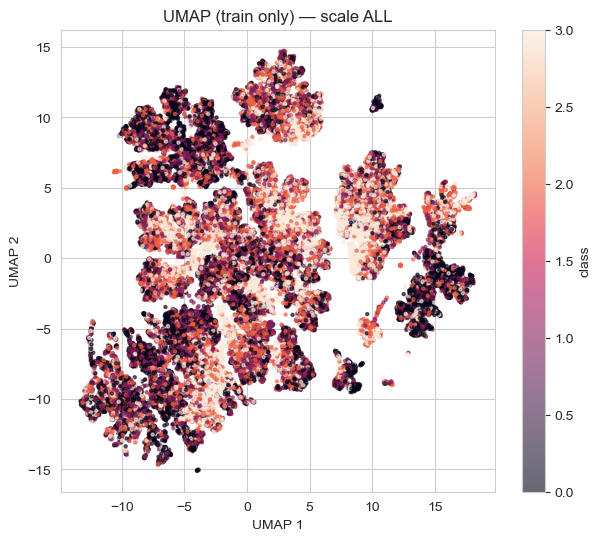

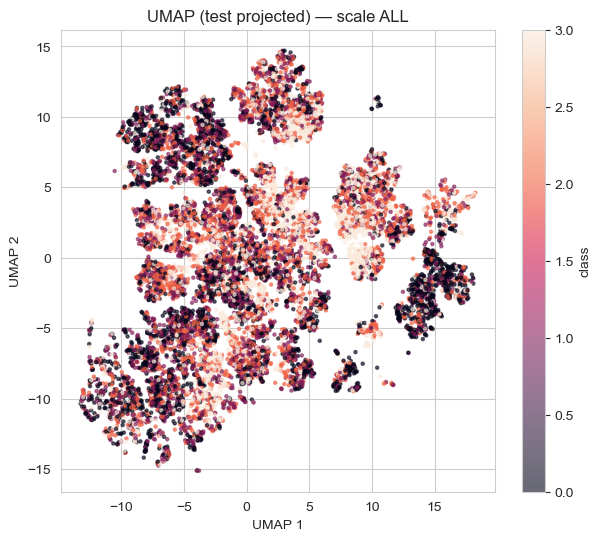

train emb shape: (58488, 2)  test emb shape: (14623, 2)


In [20]:
# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Scale ALL (fit on train only)
X_train_scaled, X_test_scaled, scaler = prepare_scale_all(X_train, X_test)

# Fit UMAP on train, transform test
reducer = umap.UMAP(n_neighbors=10, min_dist=0.5, n_components=2, random_state=42)
emb_train = reducer.fit_transform(X_train_scaled)
emb_test  = reducer.transform(X_test_scaled)

# Plot train
plt.figure(figsize=(7,6))
sc = plt.scatter(emb_train[:,0], emb_train[:,1], c=y_train, s=5, alpha=0.6)
plt.title("UMAP (train only) — scale ALL")
plt.xlabel("UMAP 1"); plt.ylabel("UMAP 2")
plt.colorbar(sc, label="class")
save_fig("umap_01_split_scale_all_train")
plt.show()

# Plot test (same embedding space)
plt.figure(figsize=(7,6))
sc = plt.scatter(emb_test[:,0], emb_test[:,1], c=y_test, s=5, alpha=0.6)
plt.title("UMAP (test projected) — scale ALL")
plt.xlabel("UMAP 1"); plt.ylabel("UMAP 2")
plt.colorbar(sc, label="class")
save_fig("umap_02_split_scale_all_test")
plt.show()

print("train emb shape:", emb_train.shape, " test emb shape:", emb_test.shape)

Scaling everything gives many separated islands of different sizes.

Interpretation: scaling the 0/1 columns can artificially amplify rare binary features.

Why? For a binary feature with proportion $p$, StandardScaler maps:

- 0 → $(0-p)/\sqrt{p(1-p)}$
- 1 → $(1-p)/\sqrt{p(1-p)}$

If $p$ is small (rare amenity), $\sqrt{p(1-p)}$ is small, so the standardised values become large in magnitude and the distance between 0 and 1 becomes huge. The UMAP neighbour graph then starts grouping listings by "has_rare_feature = 1" vs not. The islands therefore probably correspond to amenity patterns (combinations of rare and common equipment) more than to price classes.

Inside the islands, colours are still mixed: the classes vary within each amenity group. This embedding shows "types of listings", not a clean class separation.

The test listings, projected with `reducer.transform`, fall on the same islands as the training listings: the preprocessing is consistent and the split does not create a distribution shift.

#### 2) Scaling only continuous

Continuous: ['accommodates', 'bedrooms', 'beds', 'minimum_nights_avg_ntm', 'number_of_reviews', 'dist_to_center', 'bathrooms_qty', 'standing_thermal', 'score_chef_kitchen', 'score_coffee', 'score_wellness', 'score_work', 'score_view', 'score_secure', 'neigh_popularity']
Binary: ['has_ac', 'has_elevator', 'has_dishwasher', 'has_parking', 'has_balcony', 'has_washing_machine', 'rt_Entire home/apt', 'rt_Private room', 'rt_Shared room']


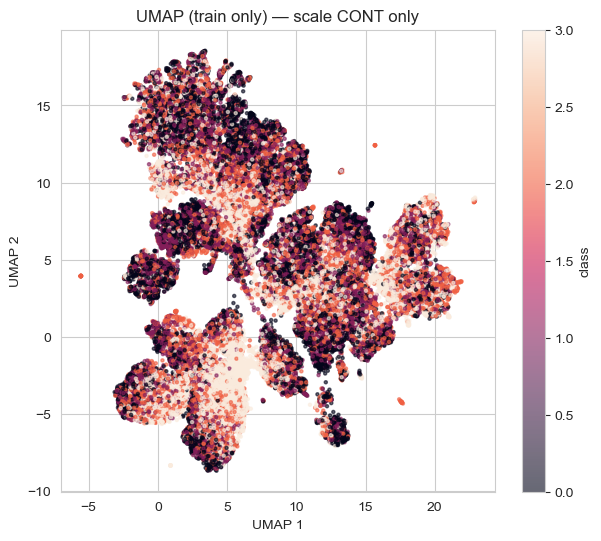

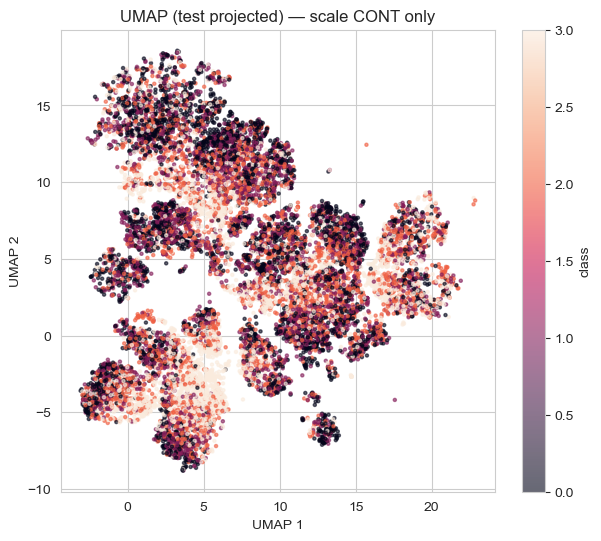

train emb shape: (58488, 2)  test emb shape: (14623, 2)


In [21]:
# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Scale continuous only (fit on train only)
X_train_prepared, X_test_prepared, scaler, cont_cols, bin_cols = prepare_scale_cont_only(X_train, X_test)

print("Continuous:", cont_cols)
print("Binary:", bin_cols)

# Fit UMAP on train, transform test
reducer = umap.UMAP(n_neighbors=10, min_dist=0.5, n_components=2, random_state=42)
emb_train = reducer.fit_transform(X_train_prepared)
emb_test  = reducer.transform(X_test_prepared)

# Plot train
plt.figure(figsize=(7,6))
sc = plt.scatter(emb_train[:,0], emb_train[:,1], c=y_train, s=5, alpha=0.6)
plt.title("UMAP (train only) — scale CONT only")
plt.xlabel("UMAP 1"); plt.ylabel("UMAP 2")
plt.colorbar(sc, label="class")
save_fig("umap_03_split_scale_cont_train")
plt.show()

# Plot test (same embedding space)
plt.figure(figsize=(7,6))
sc = plt.scatter(emb_test[:,0], emb_test[:,1], c=y_test, s=5, alpha=0.6)
plt.title("UMAP (test projected) — scale CONT only")
plt.xlabel("UMAP 1"); plt.ylabel("UMAP 2")
plt.colorbar(sc, label="class")
save_fig("umap_04_split_scale_cont_test")
plt.show()

print("train emb shape:", emb_train.shape, " test emb shape:", emb_test.shape)

Scaling only the continuous features gives fewer and larger groups than scaling everything. The embedding is still split into several blocks, driven by the remaining 0/1 features (room type, air-conditioning, dishwasher…).

Interpretation: inside the blocks, neighbourhoods are driven more by continuous intensity features (size, rooms, scores, distances, review counts…) than by rare amenity spikes.

The most expensive class (light colour) concentrates in some areas, but all the classes overlap everywhere. The class is related to the overall level of the listing (larger, better-equipped listings drift towards the higher classes), but it is not separable.

This is generally the more interpretable choice when we mix continuous + many binaries.

### UMAP without train/test split

#### 1) Scale all

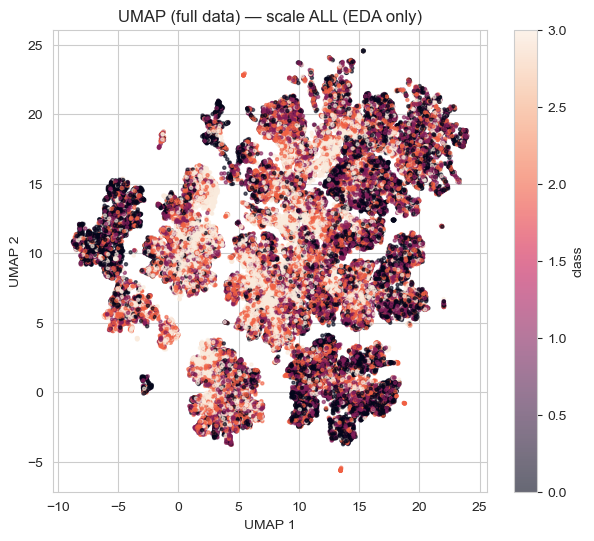

emb shape: (73111, 2)


In [22]:
# Scale ALL on full data (EDA only)
X_all_scaled, scaler = prepare_scale_all(X)

# Fit UMAP on full data
reducer = umap.UMAP(n_neighbors=10, min_dist=0.5, n_components=2, random_state=42)
emb_all = reducer.fit_transform(X_all_scaled)

plt.figure(figsize=(7,6))
sc = plt.scatter(emb_all[:,0], emb_all[:,1], c=y, s=5, alpha=0.6)
plt.title("UMAP (full data) — scale ALL (EDA only)")
plt.xlabel("UMAP 1"); plt.ylabel("UMAP 2")
plt.colorbar(sc, label="class")
save_fig("umap_05_full_scale_all")
plt.show()

print("emb shape:", emb_all.shape)

#### 2) Scale continuous only

Continuous: ['accommodates', 'bedrooms', 'beds', 'minimum_nights_avg_ntm', 'number_of_reviews', 'dist_to_center', 'bathrooms_qty', 'standing_thermal', 'score_chef_kitchen', 'score_coffee', 'score_wellness', 'score_work', 'score_view', 'score_secure', 'neigh_popularity']
Binary: ['has_ac', 'has_elevator', 'has_dishwasher', 'has_parking', 'has_balcony', 'has_washing_machine', 'rt_Entire home/apt', 'rt_Private room', 'rt_Shared room']


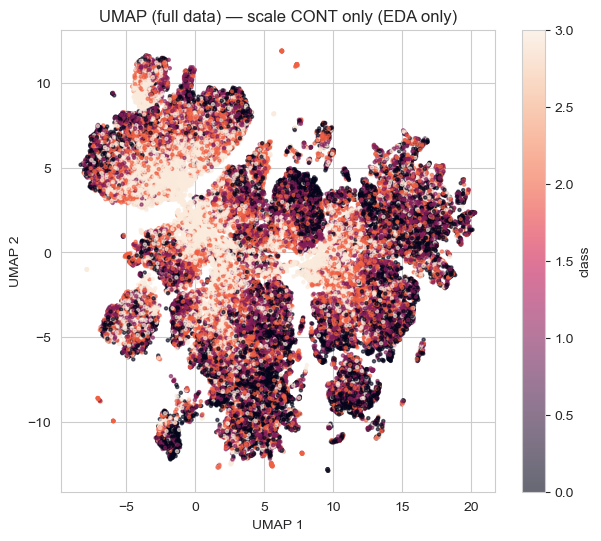

emb shape: (73111, 2)


In [23]:
# Scale continuous only on full data (EDA only)
X_all_prepared, scaler, cont_cols, bin_cols = prepare_scale_cont_only(X)

print("Continuous:", cont_cols)
print("Binary:", bin_cols)

# Fit UMAP on full data
reducer = umap.UMAP(n_neighbors=10, min_dist=0.5, n_components=2, random_state=42)
emb_all = reducer.fit_transform(X_all_prepared)

plt.figure(figsize=(7,6))
sc = plt.scatter(emb_all[:,0], emb_all[:,1], c=y, s=5, alpha=0.6)
plt.title("UMAP (full data) — scale CONT only (EDA only)")
plt.xlabel("UMAP 1"); plt.ylabel("UMAP 2")
plt.colorbar(sc, label="class")
save_fig("umap_06_full_scale_cont")
plt.show()

print("emb shape:", emb_all.shape)

Fitted on all 73,111 listings, the two embeddings show the same picture as the train-only ones: many islands when everything is standardised, fewer and larger blocks when only the continuous features are scaled, and mixed classes everywhere. The structure does not depend on the train/test split.

## What is the added value of UMAP compared to PCA?

PCA: linear projection --> components are interpretable “PC1 is driven by these variables" and
quantifiable “PC1+PC2 explain X% variance.”

UMAP : non-linear and neighborhood-driven --> not an “explained variance” curve

UMAP’s advantage is local structure discovery: 

Here, in this tabular, we have a mixed of continuous and binary variables. The relationships between variables can be non-linear (e.g. room type × capacity × amenities × location). UMAP can reveal non-linear grouping patterns when similarity is not well-modeled by linear directions (such as here in this specific tabular).  

A nonlinear method can reveal sub-populations (“islands”) that PCA sometimes spreads out into elongated shapes, because PCA does not “bend” the space: it only projects it. 

Therefore, it is better to use PCA to interpret the main linear factors and explain the overall structure and use UMAP to visualize local nonlinear patterns, identify archetypes/outliers, and check whether the price classes seem to overlap strongly or not.

## On which feature can we do UMAP? 

The key principle is to choose subsets that support an interpretive question and we shall recall that UMAP is sensitive to the distance metric.

- Full explanatory set as a recommended baseline: UMAP is mainly used as an unsupervised method. So, we include all explanatory variables; the target is only used to colour the points.
- Location and market proxies: dist_to_center, neigh_popularity, number_of_reviews, minimum_nights_avg_ntm --> focuses on spatial/market dynamics (not run here)
- Capacity & configuration: accommodates, bedrooms, beds, bathrooms_qty --> would test whether listing “size” alone forms clear archetypes and how it relates to target_class (not run here).

LDA

PCA looks for the directions where the data spreads out most. LDA instead looks for the combinations of features that push the four price classes as far apart as possible (between-class variance relative to within-class variance). With 4 classes it can build at most K − 1 = 3 discriminant axes. It is also a classifier: a Gaussian model with a covariance matrix shared by the classes.

Accuracy: 48.11%
Confusion matrix: 
[[2555  767  425   76]
 [1282 1043  907  258]
 [ 714  696 1395  855]
 [ 423  304  881 2042]]


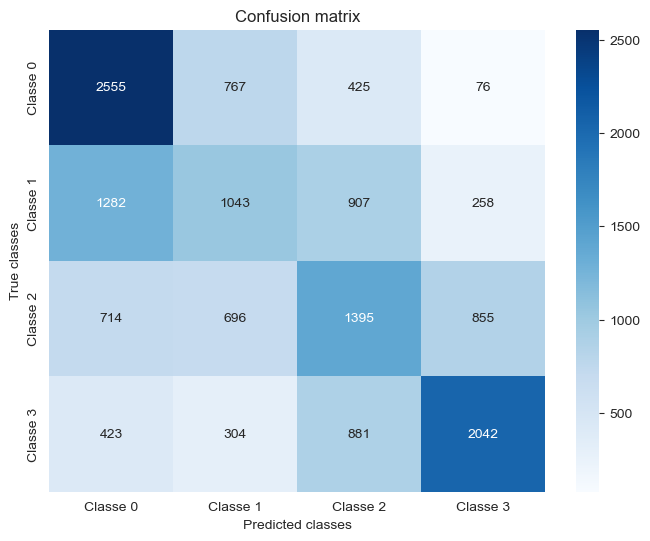

In [24]:
#LDA 
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

#test set predicted classes
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)
y_pred = lda.predict(X_test)

#accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2%}")

#confusion matrix
cm = confusion_matrix(y_test, y_pred)
print(f"Confusion matrix: \n{cm}")

#visualization 
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=[f'Classe {i}' for i in range(4)],
            yticklabels=[f'Classe {i}' for i in range(4)])
plt.title('Confusion matrix')
plt.xlabel('Predicted classes')
plt.ylabel('True classes')
save_fig("lda_01_confusion_matrix")
plt.show()

LDA reaches 48.1% accuracy (25% by chance). It identifies the cheapest listings (class 0: 2,555 of 3,823 correct, 67%) and the most expensive ones (class 3: 2,042 of 3,650, 56%) best. The middle classes are hard:
- class 1 is predicted as class 0 more often (1,282) than correctly (1,043, 30%);
- class 2 is spread over classes 1, 2 and 3 (1,395 correct, 38%).


LDA Method
Reduced dimensions: 24 → 3
Explained variance: [0.91726509 0.07553261 0.0072023 ]


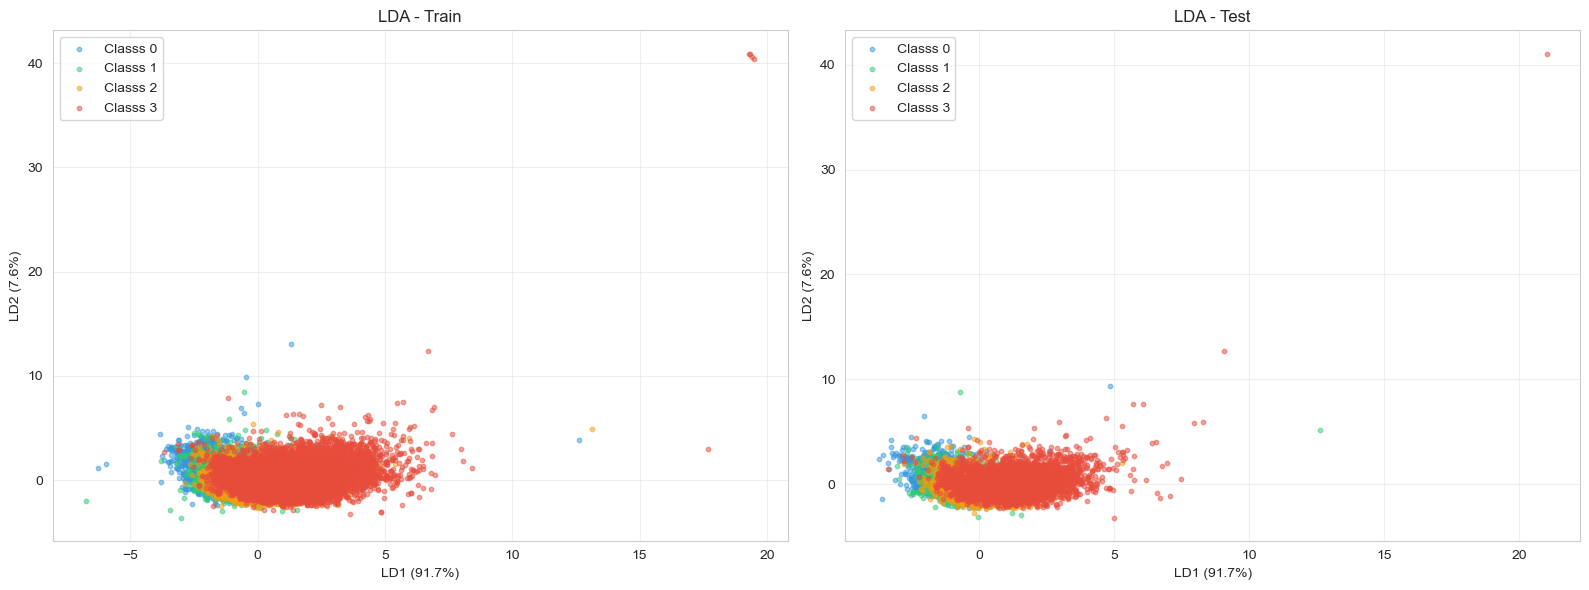

In [25]:
#LDA
colors_class = ['#3498db', '#2ecc71', '#f39c12', '#e74c3c']

print("\n" + "=" * 60)
print("LDA Method")
print("=" * 60)

lda = LinearDiscriminantAnalysis(n_components=3) #3 composantes pour 4 classes
X_train_lda = lda.fit_transform(X_train, y_train)
X_test_lda = lda.transform(X_test)

print(f"Reduced dimensions: {X_train.shape[1]} → {X_train_lda.shape[1]}")
print(f"Explained variance: {lda.explained_variance_ratio_}")

#2D visualisation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (X_lda, y_set, title) in zip(axes, 
    [(X_train_lda, y_train, 'Train'), (X_test_lda, y_test, 'Test')]):
    
    for classe in range(4):
        mask = y_set == classe
        ax.scatter(X_lda[mask, 0], X_lda[mask, 1], 
                  c=colors_class[classe], label=f'Classs {classe}', alpha=0.5, s=10)
    
    ax.set_title(f"LDA - {title}")
    ax.set_xlabel(f"LD1 ({lda.explained_variance_ratio_[0]:.1%})")
    ax.set_ylabel(f"LD2 ({lda.explained_variance_ratio_[1]:.1%})")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
save_fig("lda_02_projection_train_test")
plt.show()

The plots show a colour transition along the first axis, which carries 91.7% of the between-class separation. The second axis carries only 7.6% and the third 0.7%. Classes 0 to 3 are ordered along LD1, but the middle classes overlap heavily, so a linear model only reaches about 48%.

The train and test plots look alike: LDA has few parameters and does not overfit.

The few points far from the rest (top right) are the data anomalies already seen in the PCA (buildings declared as one listing with 30 bedrooms). They mostly belong to class 3, but they are not a "luxury segment".

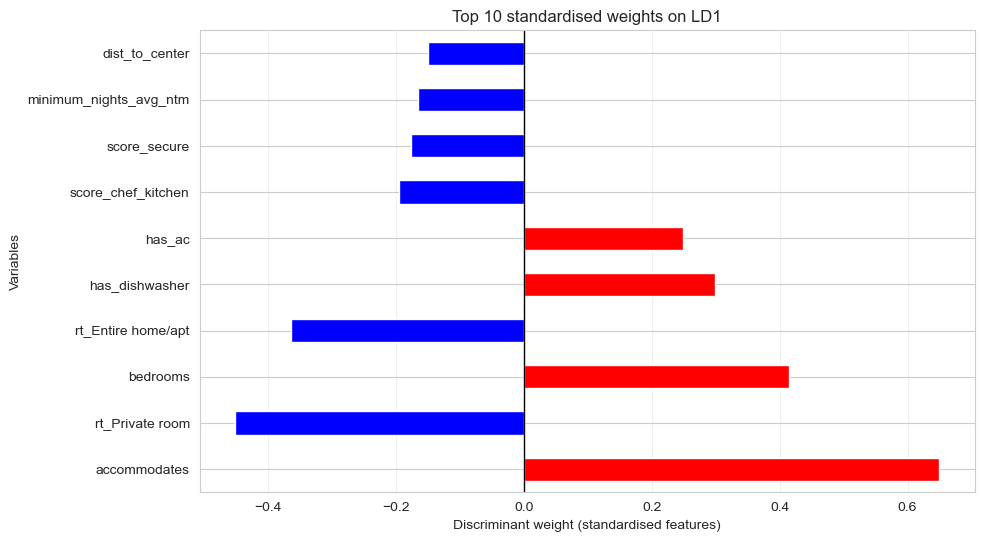

In [26]:
#weights of the discriminant axes. They are in lda.scalings_ (lda.coef_ holds the per-class decision
# coefficients, not the LD axes). LDA is refitted on standardised features so that weights are comparable
# across variables; the projection and the predictions do not change with this rescaling.
scaler_lda = StandardScaler().fit(X_train)
lda_std = LinearDiscriminantAnalysis(n_components=3).fit(scaler_lda.transform(X_train), y_train)
Z_std = lda_std.transform(scaler_lda.transform(X_train))
# the sign of an LD axis is arbitrary: orient each one like the projection plotted above
signs = np.sign([np.corrcoef(Z_std[:, k], X_train_lda[:, k])[0, 1] for k in range(3)])
ld_weights = pd.DataFrame(lda_std.scalings_[:, :3] * signs, index=X.columns, columns=['LD1', 'LD2', 'LD3'])

#sorting
top_coeffs = ld_weights['LD1'].reindex(ld_weights['LD1'].abs().sort_values(ascending=False).index).head(10) #top 10 features

#plot
plt.figure(figsize=(10, 6))
top_coeffs.plot(kind='barh', color=['red' if x > 0 else 'blue' for x in top_coeffs])
plt.title("Top 10 standardised weights on LD1")
plt.xlabel("Discriminant weight (standardised features)")
plt.ylabel("Variables")
plt.axvline(x=0, color='black', linestyle='-', linewidth=1)
plt.grid(axis='x', alpha=0.3)
save_fig("lda_03_LD1_weights")
plt.show()

The largest positive weights on LD1 are `accommodates` and `bedrooms`, followed by the dishwasher and air-conditioning. The room-type dummies get large negative weights.

Caution: the weights should not be read one by one.
- The `rt_*` dummies are almost collinear: they sum to one, except for the few hotel rooms. Both "entire home" and "private room" therefore get a negative weight, relative to hotel rooms.
- `accommodates`, `beds` and `bedrooms` are strongly correlated.

The structure correlations below (correlation of each feature with the LD axis) are the reliable reading: LD1 is a **size** axis. Neighbourhood popularity is not a driver (correlation −0.20 with LD1).

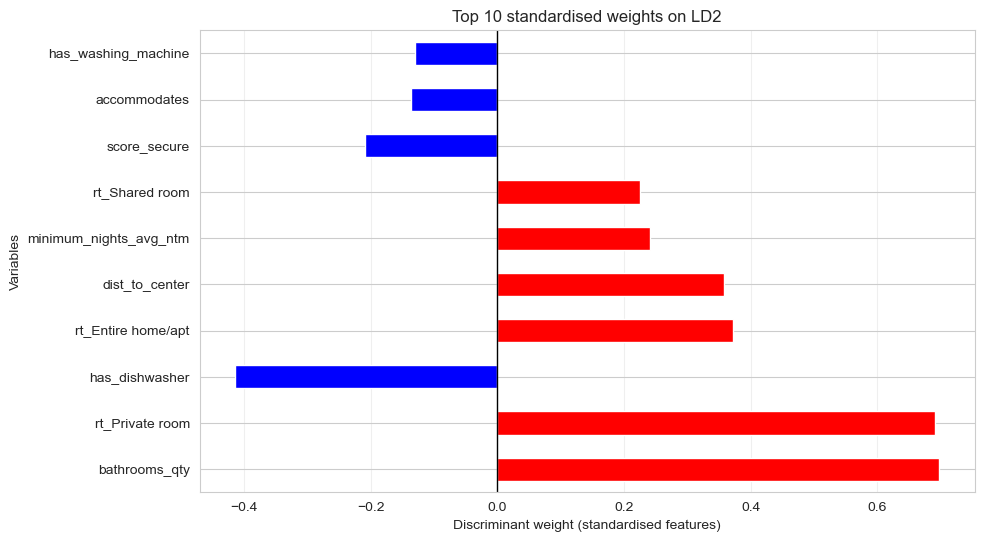

In [27]:
#LD2 weights (standardised features, same orientation as the projection plot)
top_coeffs = ld_weights['LD2'].reindex(ld_weights['LD2'].abs().sort_values(ascending=False).index).head(10)

#plot
plt.figure(figsize=(10, 6))
top_coeffs.plot(kind='barh', color=['red' if x > 0 else 'blue' for x in top_coeffs])
plt.title("Top 10 standardised weights on LD2")
plt.xlabel("Discriminant weight (standardised features)")
plt.ylabel("Variables")
plt.axvline(x=0, color='black', linestyle='-', linewidth=1)
plt.grid(axis='x', alpha=0.3)
save_fig("lda_04_LD2_weights")
plt.show()

LD2 carries only 7.6% of the separation. Its largest weights are positive for `bathrooms_qty` and private rooms, and negative for the dishwasher. The structure correlations below show what it measures: bathrooms_qty +0.56, rt_Private room +0.40, dist_to_center +0.36, has_dishwasher −0.37, rt_Entire home/apt −0.37.

LD2 roughly isolates private rooms far from the centre with several (possibly shared) bathrooms — hostel or guest-house style listings — from equipped flats. It adds little to the classification.

In [28]:
#LDA coordinates
lda_coords = pd.DataFrame(X_train_lda, columns=[f'LD{i+1}' for i in range(X_train_lda.shape[1])])

#correlations between X_train and the LD axes
structure_matrix = pd.concat([X_train.reset_index(drop=True), lda_coords], axis=1).corr()
final_corr = structure_matrix.loc[X.columns, ['LD1', 'LD2']]

print(final_corr.sort_values('LD1', ascending=False).round(3))

                          LD1    LD2
accommodates            0.843  0.058
bedrooms                0.800  0.270
beds                    0.581  0.087
bathrooms_qty           0.573  0.556
has_dishwasher          0.443 -0.372
has_ac                  0.318 -0.002
score_wellness          0.308  0.034
standing_thermal        0.299 -0.069
has_washing_machine     0.269 -0.201
score_work              0.193 -0.087
score_chef_kitchen      0.190 -0.283
has_elevator            0.176 -0.076
rt_Entire home/apt      0.167 -0.365
has_balcony             0.139 -0.036
has_parking             0.109  0.025
score_coffee            0.107 -0.239
score_view              0.065 -0.024
rt_Shared room         -0.064  0.158
dist_to_center         -0.113  0.357
number_of_reviews      -0.117 -0.090
score_secure           -0.121 -0.299
minimum_nights_avg_ntm -0.161  0.236
rt_Private room        -0.194  0.396
neigh_popularity       -0.200  0.043


The LD1 axis is (unsurprisingly) driven by guest capacity and property size: accommodates (0.84), bedrooms (0.80), beds (0.58) and bathrooms (0.57). The primary factor of Paris prices in these data is physical space.

The LD2 axis contrasts the configuration of the listing:
- positive side: private rooms, the distance from the centre, the number of bathrooms;
- negative side: entire homes and equipment such as dishwashers.

Class 0 vs rest: AUC = 0.815
Class 1 vs rest: AUC = 0.669
Class 2 vs rest: AUC = 0.670
Class 3 vs rest: AUC = 0.828


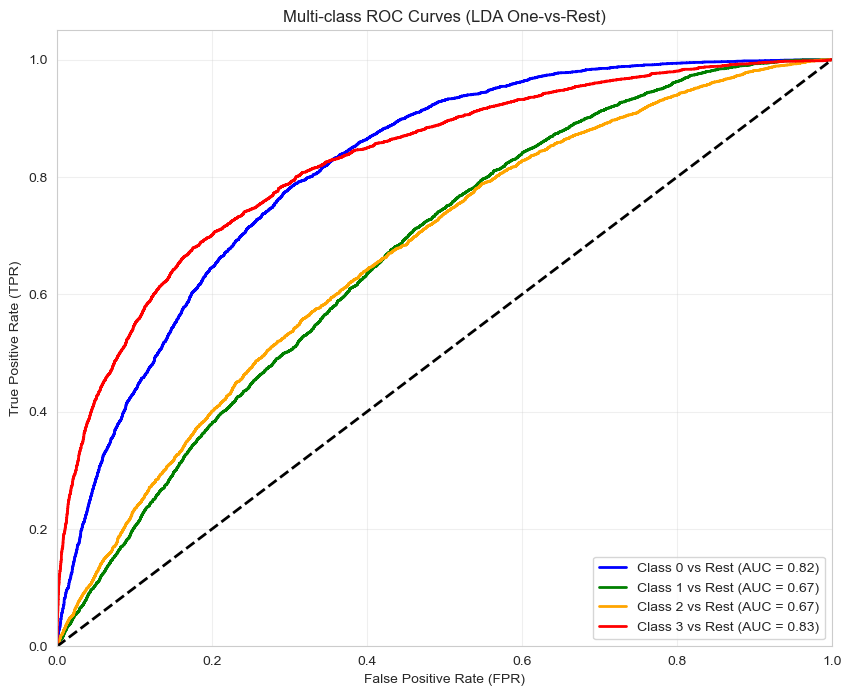

In [29]:
#ROC curves
#one vs rest per class to evaluate performance by quartile

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

#binarize the target 
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3])
n_classes = y_test_bin.shape[1]

#get predicted probabilities from LDA
y_score = lda.predict_proba(X_test)

#compute and plot curves
plt.figure(figsize=(10, 8))
colors = ['blue', 'green', 'orange', 'red']

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    print(f"Class {i} vs rest: AUC = {roc_auc:.3f}")
    plt.plot(fpr, tpr, color=colors[i], lw=2,
             label=f'Class {i} vs Rest (AUC = {roc_auc:.2f})')

#chart styling
plt.plot([0, 1], [0, 1], 'k--', lw=2) #randomization
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Multi-class ROC Curves (LDA One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
save_fig("lda_05_roc_curves")
plt.show()

The ROC curves confirm the pattern of the confusion matrix. Classes 0 and 3 are well isolated from the rest (AUC 0.82 and 0.83). Classes 1 and 2 are much harder (AUC 0.67 for both): a listing of a middle class looks like its neighbours on both sides.

CART

A classification tree splits the data recursively with simple rules ("bedrooms ≤ 1.5?"), choosing at each node the split that most reduces the Gini impurity.
1. We first grow a depth-3 tree, small enough to read.
2. We then let the tree grow fully and prune it by **cost-complexity pruning**: each leaf costs α, and α is chosen by 5-fold cross-validation with the **1-SE rule** (the simplest tree whose CV score is within one standard error of the best).

METHOD: CART
Accuracy: 45.70%


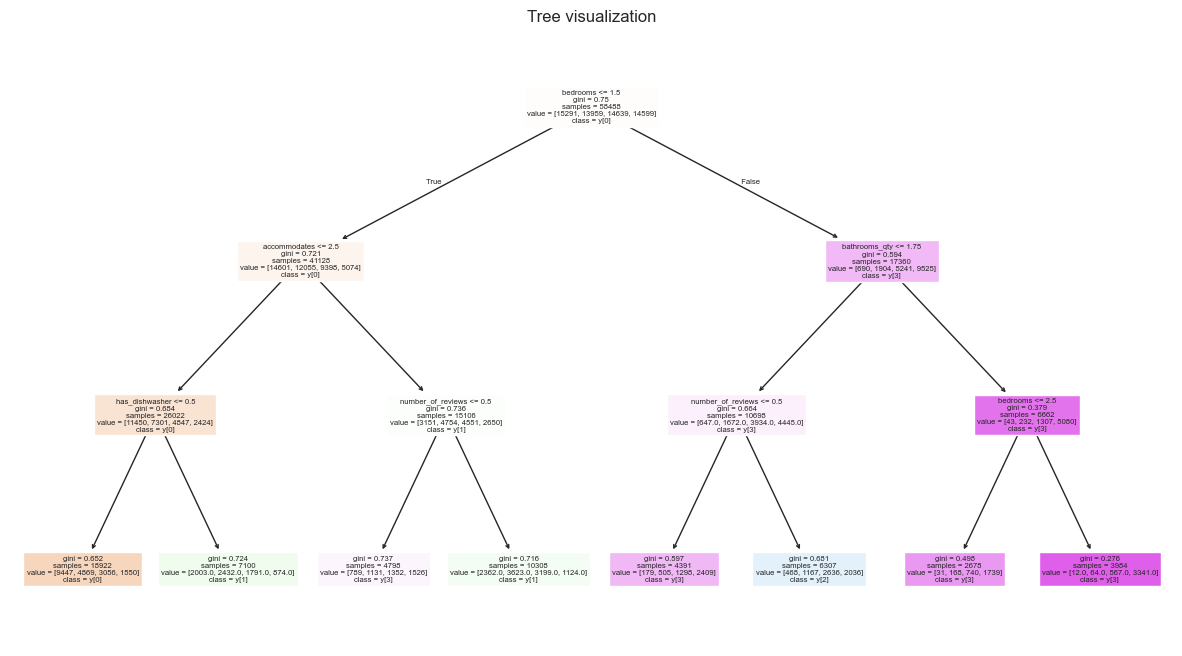

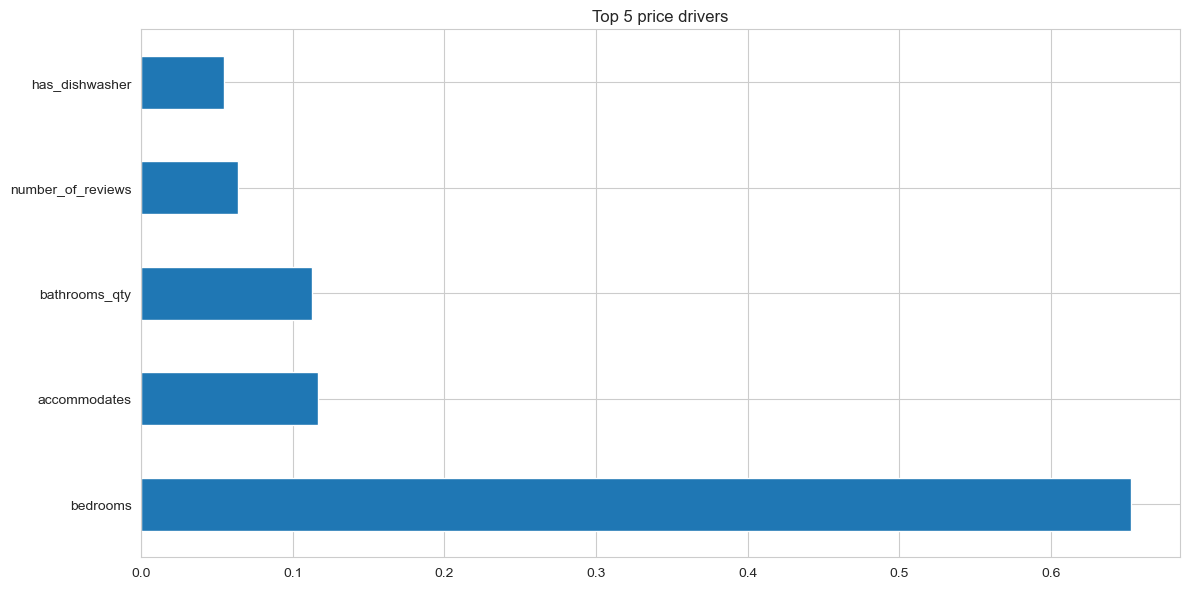

In [30]:
print("=" * 60)
print("METHOD: CART")
print("=" * 60)

#train 
cart = DecisionTreeClassifier(max_depth=3, random_state=42) #a depth of 3 keeps the tree simple enough to read
cart.fit(X_train, y_train)

#evaluation
y_pred = cart.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")

#visualizing the tree
plt.figure(figsize=(15, 8))
plot_tree(cart, feature_names=X.columns, filled=True, class_names=True)
plt.title("Tree visualization")
save_fig("cart_01_tree_depth3")
plt.show()

#feature mportance
importance = pd.Series(cart.feature_importances_, index=X.columns).sort_values(ascending=False)
importance.head(5).plot(kind='barh', title="Top 5 price drivers")
plt.tight_layout()
save_fig("cart_02_depth3_top5_importance")
plt.show()

The depth-3 tree reaches 45.7% accuracy. Its logic:
- the root splits on **bedrooms ≤ 1.5**;
- on the small side, **accommodates ≤ 2.5**; on the large side, **bathrooms_qty ≤ 1.75**;
- the third level uses the dishwasher, the number of bedrooms, and **number_of_reviews = 0 vs > 0**.

Listings with 2 or more bedrooms and 2 or more bathrooms are Luxury in 76% of cases (5,080 of 6,662 training listings).

Listings without any review are noticeably more expensive. In Paris their mean class is 1.84 against 1.31 for reviewed listings. A plausible explanation (not tested here) is that many are new or rarely booked listings with ambitious prices, possibly created ahead of the 2024 Olympics.

The importance plot (Gini) confirms that size dominates: bedrooms alone accounts for 65% of the impurity reduction of this small tree.

Best CV accuracy: 0.5305 (alpha=9.39e-05), 1-SE cutoff: 0.5295
The largest alpha that stays above the cutoff is: 9.39e-05


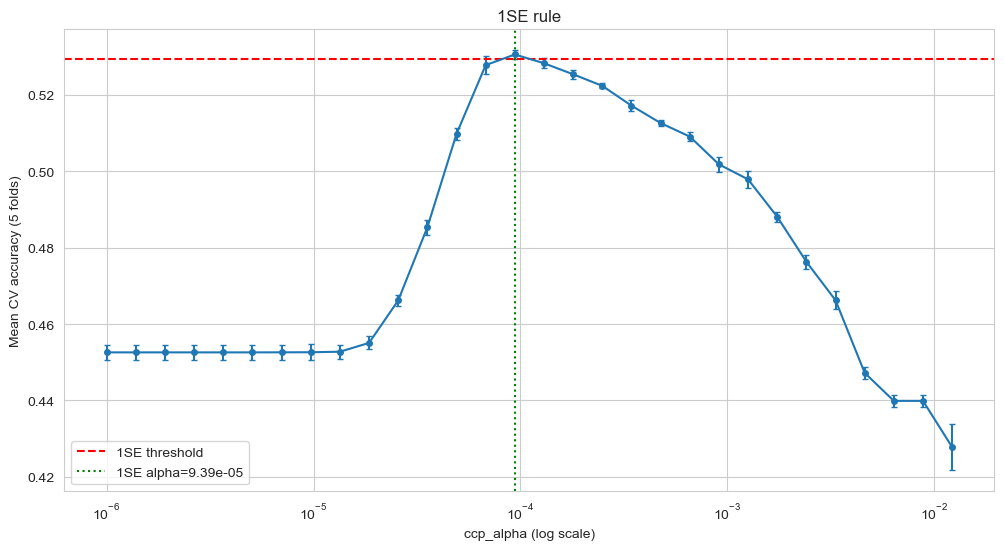

Pruned tree: depth 16, 216 leaves
Pruned Tree Accuracy: 52.23%


In [31]:
#cost complexity path of the fully grown tree (the path of the depth-3 tree above would only contain a handful of alphas)
from sklearn.model_selection import cross_val_score

full_tree = DecisionTreeClassifier(random_state=42)
path = full_tree.cost_complexity_pruning_path(X_train, y_train)
# the full path has thousands of alphas: 30 log-spaced values over its range are enough for the 1-SE rule
ccp_alphas = np.geomspace(1e-6, path.ccp_alphas[-2], 30)

#finding the best alpha
scores_means = []
scores_ses = []

for alpha in ccp_alphas:
    cv_scores = cross_val_score(DecisionTreeClassifier(ccp_alpha=alpha, random_state=42), X_train, y_train, cv=5, n_jobs=-1)
    scores_means.append(cv_scores.mean())
    scores_ses.append(cv_scores.std(ddof=1) / np.sqrt(len(cv_scores))) # standard error of the CV mean

#1-SE Rule: the simplest tree whose CV score is within one standard error of the best one
best_idx = np.argmax(scores_means)
cutoff = scores_means[best_idx] - scores_ses[best_idx]

#largest alpha that stays above the cutoff
optimal_alpha = max([alpha for i, alpha in enumerate(ccp_alphas) if scores_means[i] >= cutoff])
print(f"Best CV accuracy: {scores_means[best_idx]:.4f} (alpha={ccp_alphas[best_idx]:.2e}), 1-SE cutoff: {cutoff:.4f}")
print(f"The largest alpha that stays above the cutoff is: {optimal_alpha:.2e}")

#plot
plt.errorbar(ccp_alphas, scores_means, yerr=scores_ses, marker='o', markersize=4, capsize=2)
plt.xscale('log')
plt.axhline(cutoff, color='red', linestyle='--', label='1SE threshold')
plt.axvline(optimal_alpha, color='green', linestyle=':', label=f'1SE alpha={optimal_alpha:.2e}')
plt.xlabel('ccp_alpha (log scale)')
plt.ylabel('Mean CV accuracy (5 folds)')
plt.title('1SE rule')
plt.legend()
save_fig("cart_03_ccp_alpha_1se_rule")
plt.show()

#pruned tree
pruned_cart = DecisionTreeClassifier(ccp_alpha=optimal_alpha, random_state=42)
pruned_cart.fit(X_train, y_train)

print(f"Pruned tree: depth {pruned_cart.get_depth()}, {pruned_cart.get_n_leaves()} leaves")
print(f"Pruned Tree Accuracy: {pruned_cart.score(X_test, y_test):.2%}")

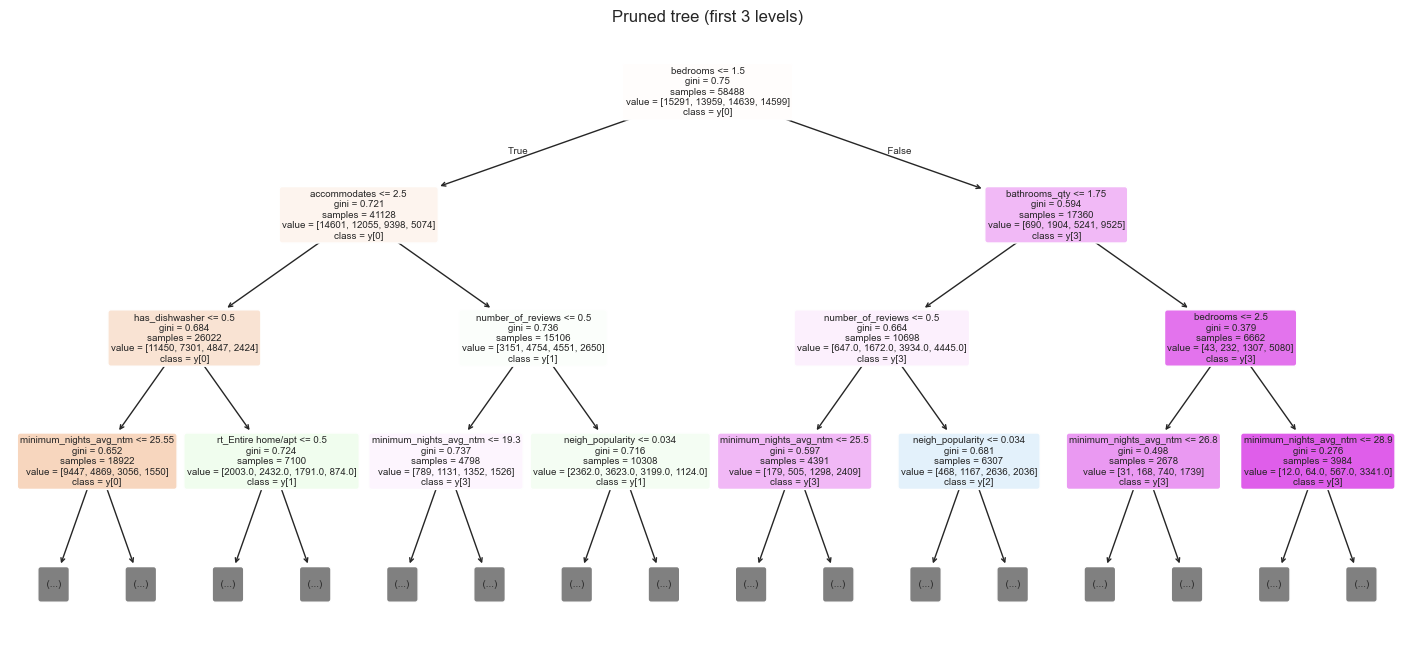

Pruned tree - top 5 features (Gini importance):
bedrooms                  0.380
neigh_popularity          0.104
minimum_nights_avg_ntm    0.093
accommodates              0.082
number_of_reviews         0.076


In [32]:
#pruned tree (only the first 3 levels are drawn, the full tree is too large to read)
plt.figure(figsize=(18, 8))
plot_tree(pruned_cart,
          max_depth=3,
          feature_names=X.columns,
          class_names=True,
          filled=True,
          rounded=True,
          fontsize=7)

plt.title("Pruned tree (first 3 levels)")
save_fig("cart_04_pruned_tree_top_levels")
plt.show()

importance = pd.Series(pruned_cart.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Pruned tree - top 5 features (Gini importance):")
print(importance.head(5).round(3).to_string())

Accuracy: 52.23%


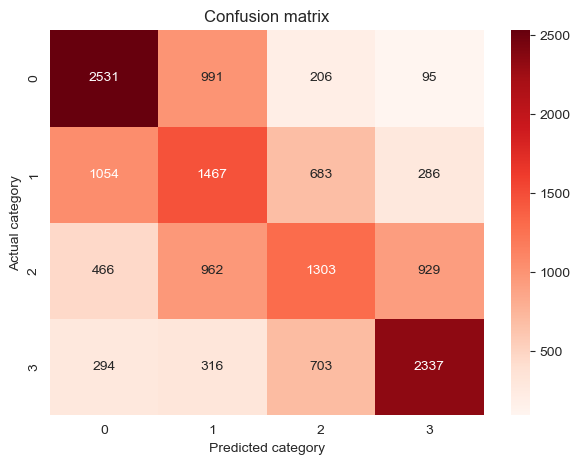

In [33]:
#pridiction using the pruned model
y_pred = pruned_cart.predict(X_test)

#score
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")

#Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Reds')
plt.title("Confusion matrix")
plt.xlabel("Predicted category")
plt.ylabel("Actual category")
save_fig("cart_05_pruned_confusion_matrix")
plt.show()

After pruning, the tree keeps 216 leaves (depth 16) and reaches **52.2%** accuracy, against 45.7% for the depth-3 tree and 48.1% for LDA. Here the 1-SE rule keeps the alpha with the best CV score: the next, larger alpha already falls below the cutoff. The tree captures the extremes well, but still finds the middle classes hard.

The listing data cannot fully separate the Paris market: a small studio in a sought-after district can cost as much as a large flat further out, and the features say nothing about surface area, decoration or view.

The pruned tree beats LDA by 4 points. Non-linear rules and interactions (size × room type × reviews) therefore matter, and the price classes are not linearly separable. Both models do well on the extreme classes (0 and 3) and poorly in the middle. Averaging many trees (bagging, random forests) should reduce the variance of a single tree; this is what the next sections test.

In [34]:
# Same 24 features and same 80/20 split as the previous sections, so that every model is scored on the same test set
X = df_paris.drop(columns=['target_class', 'price_clean', 'city_label'] + pg_cols).astype(float)
y = df_paris['target_class'].values

CLASS_COLORS = ['#2196F3', '#4CAF50', '#FF9800', '#F44336']
CLASS_LABELS = ['Cl.0 – Very low', 'Cl.1 – Low-mid', 'Cl.2 – High-mid', 'Cl.3 – Very high']
CLASS_SHORT  = ['Cl.0', 'Cl.1', 'Cl.2', 'Cl.3']

print(f"Dataset: {df_paris.shape[0]} rows x {X.shape[1]} features")
print(f"target_class distribution:")
for c in range(4):
    print(f"  Class {c}: {np.sum(y==c):>5d} obs ({np.mean(y==c)*100:.1f}%)")

X_train, X_test, y_train, y_test = train_test_split(
    X.values, y, test_size=0.2, random_state=42, stratify=y
)

Dataset: 73111 rows x 24 features
target_class distribution:
  Class 0: 19114 obs (26.1%)
  Class 1: 17449 obs (23.9%)
  Class 2: 18299 obs (25.0%)
  Class 3: 18249 obs (25.0%)


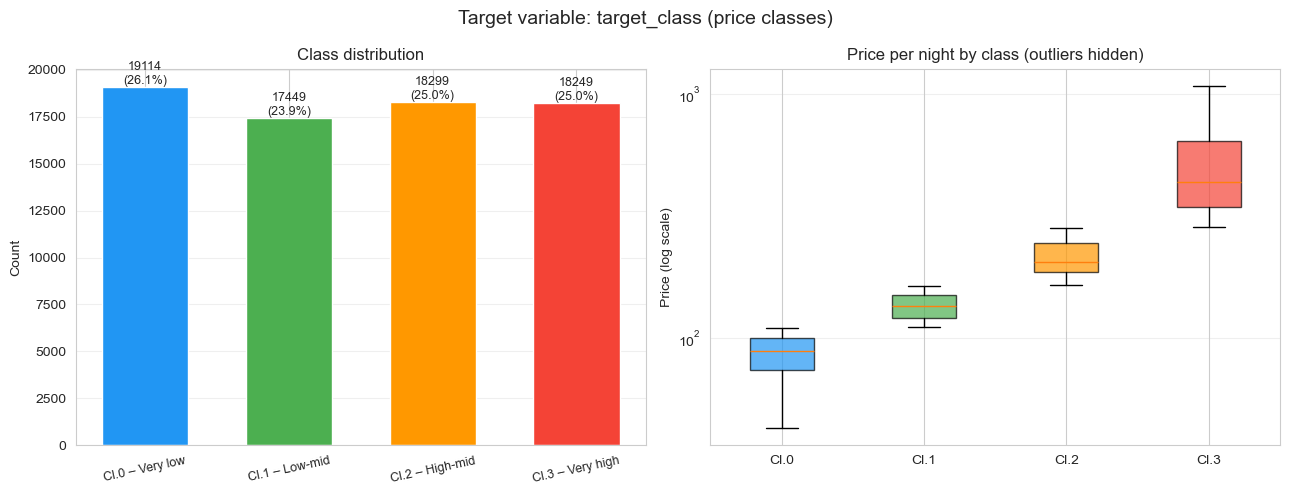

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Target variable: target_class (price classes)", fontsize=14)

counts = pd.Series(y).value_counts().sort_index()
bars = axes[0].bar(range(4), counts.values, color=CLASS_COLORS, edgecolor='white', width=0.6)
axes[0].set_xticks(range(4))
axes[0].set_xticklabels(CLASS_LABELS, rotation=12, fontsize=9)
axes[0].set_ylabel("Count")
axes[0].set_title("Class distribution")
for bar, v in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, v + 5,
                 f'{v}\n({v/len(y)*100:.1f}%)', ha='center', va='bottom', fontsize=9)
axes[0].grid(axis='y', alpha=0.3)

# Price distribution per class (log scale): the classes are quartiles of price_clean
bp = axes[1].boxplot([df_paris.loc[df_paris['target_class'] == c, 'price_clean'] for c in range(4)],
                     patch_artist=True, tick_labels=CLASS_SHORT, showfliers=False)
for patch, color in zip(bp['boxes'], CLASS_COLORS):
    patch.set_facecolor(color); patch.set_alpha(0.7)
axes[1].set_yscale('log')
axes[1].set_title("Price per night by class (outliers hidden)")
axes[1].set_ylabel("Price (log scale)")
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
save_fig("bootstrap_01_target_classes")
plt.show()

--- BOOTSTRAP: stability of the class proportions ---



  95% CI per class:
    Class 0: 0.262 +/- 0.0016  CI95% [0.258, 0.265]
    Class 1: 0.239 +/- 0.0016  CI95% [0.235, 0.242]
    Class 2: 0.250 +/- 0.0015  CI95% [0.247, 0.253]
    Class 3: 0.250 +/- 0.0016  CI95% [0.247, 0.253]

  Quartile boundaries:
    Q1 = 110: 1187 listings priced exactly at the boundary
    Q2 = 164: 132 listings priced exactly at the boundary
    Q3 = 284: 50 listings priced exactly at the boundary


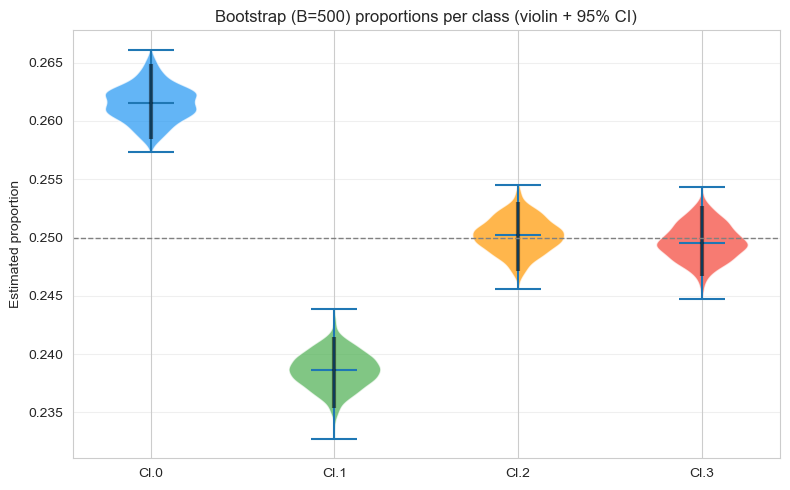

In [36]:
print("--- BOOTSTRAP: stability of the class proportions ---")
# The classes are price quartiles, so their proportions are ~25% by construction: this resampling only shows how
# precisely they are estimated. The bootstrap of the model metrics is at the end of the notebook.

N_BOOT = 500
bootstrap_props  = {c: [] for c in range(4)}

for _ in range(N_BOOT):
    s = resample(y, replace=True, n_samples=len(y))
    for c in range(4):
        bootstrap_props[c].append(np.mean(s == c))

print(f"\n  95% CI per class:")
for c in range(4):
    p = np.array(bootstrap_props[c])
    print(f"    Class {c}: {p.mean():.3f} +/- {p.std():.4f}  "
          f"CI95% [{np.percentile(p,2.5):.3f}, {np.percentile(p,97.5):.3f}]")

# Why not exactly 25%: pd.qcut puts listings priced exactly at a quartile boundary in the lower class
print("\n  Quartile boundaries:")
for q, b in df_paris['price_clean'].quantile([0.25, 0.5, 0.75]).items():
    print(f"    Q{int(q*4)} = {b:.0f}: {(df_paris['price_clean'] == b).sum()} listings priced exactly at the boundary")

fig2, ax2 = plt.subplots(figsize=(8, 5))
parts = ax2.violinplot([bootstrap_props[c] for c in range(4)], positions=range(4), showmedians=True,
                       showextrema=True)
for body, color in zip(parts['bodies'], CLASS_COLORS):
    body.set_facecolor(color); body.set_alpha(0.7)
# 95% CI
for c in range(4):
    p = np.array(bootstrap_props[c])
    ax2.vlines(c, np.percentile(p, 2.5), np.percentile(p, 97.5),
               color='black', lw=3, alpha=0.5)
ax2.axhline(0.25, color='grey', linestyle='--', lw=1)
ax2.set_xticks(range(4))
ax2.set_xticklabels(CLASS_SHORT)
ax2.set_title(f"Bootstrap (B={N_BOOT}) proportions per class (violin + 95% CI)")
ax2.set_ylabel("Estimated proportion")
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
save_fig("bootstrap_02_class_proportions")
plt.show()

The class shares are 26.1 / 23.9 / 25.0 / 25.0%, with bootstrap intervals of about ±0.3 point. They are not exactly 25% because 1,187 listings are priced exactly at the first quartile (110), and `pd.qcut` puts them all in class 0. This bootstrap only checks the construction of the target. The bootstrap that matters — confidence intervals of the model scores — is at the end of the notebook.

--- BAGGING: error vs B (OOB and test) ---


  Single CART (test error): 0.4855
  Min OOB error: 0.4553  (B=130), test error at that B: 0.4609


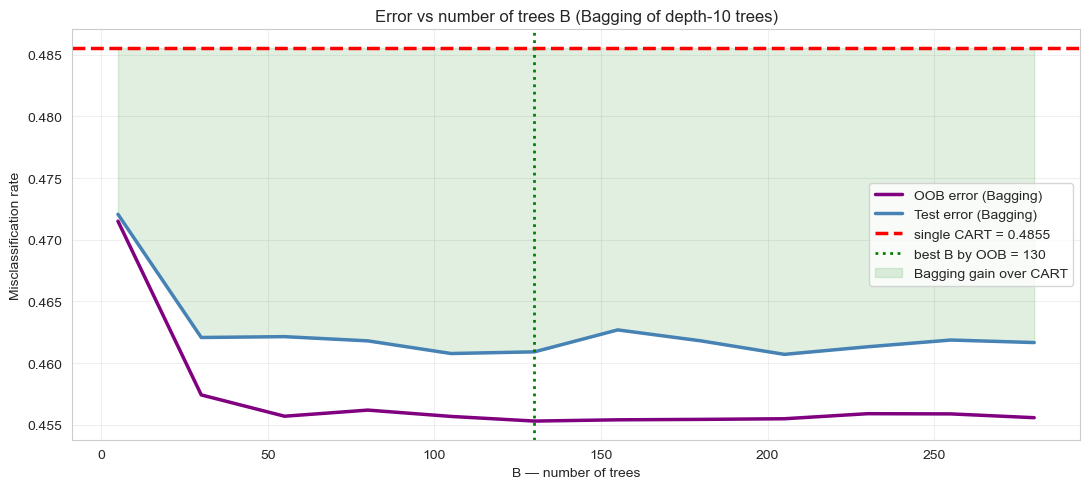

In [37]:
print("--- BAGGING: error vs B (OOB and test) ---")

# step=25 -> 12 points, the curve still shows convergence
B_range = list(range(5, 301, 25))

# max_depth=10: biggest speed gain - unbounded trees are very slow on 58k rows
# max_samples=0.5: each tree trains on 50% of X_train
bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=10),
    n_estimators=max(B_range),
    max_samples=0.5,
    bootstrap=True,
    random_state=42, n_jobs=-1
).fit(X_train, y_train)

# Errors of the ensemble made of the first B trees. The OOB error only uses, for each training row, the trees
# that did not draw it, so B is chosen without looking at the test set.
oob_votes  = np.zeros((len(X_train), 4))
test_votes = np.zeros((len(X_test), 4))
oob_errs, test_errs = [], []
for b, (tree, rows) in enumerate(zip(bag.estimators_, bag.estimators_samples_), start=1):
    oob = np.ones(len(X_train), dtype=bool)
    oob[rows] = False
    oob_votes[oob] += tree.predict_proba(X_train[oob])
    test_votes += tree.predict_proba(X_test)
    if b in B_range:
        seen = oob_votes.sum(axis=1) > 0
        oob_errs.append(1 - accuracy_score(y_train[seen], oob_votes[seen].argmax(axis=1)))
        test_errs.append(1 - accuracy_score(y_test, test_votes.argmax(axis=1)))

# Single tree test error
cart_ref = DecisionTreeClassifier(max_depth=10, random_state=42)
cart_ref.fit(X_train, y_train)
err_cart_ref = 1 - accuracy_score(y_test, cart_ref.predict(X_test))
print(f"  Single CART (test error): {err_cart_ref:.4f}")

# Best B, chosen on the OOB error
best_B   = B_range[np.argmin(oob_errs)]
best_err = min(oob_errs)
print(f"  Min OOB error: {best_err:.4f}  (B={best_B}), test error at that B: {test_errs[np.argmin(oob_errs)]:.4f}")

fig3, ax3 = plt.subplots(figsize=(11, 5))
ax3.plot(B_range, oob_errs, color='purple', lw=2.5, label='OOB error (Bagging)')
ax3.plot(B_range, test_errs, color='steelblue', lw=2.5, label='Test error (Bagging)')
ax3.axhline(err_cart_ref, color='red', linestyle='--', lw=2.5,
            label=f'single CART = {err_cart_ref:.4f}')
ax3.axvline(best_B, color='green', linestyle=':', lw=2,
            label=f'best B by OOB = {best_B}')
ax3.fill_between(B_range, test_errs, err_cart_ref,
                 where=[e < err_cart_ref for e in test_errs],
                 alpha=0.12, color='green', label='Bagging gain over CART')
ax3.set_title("Error vs number of trees B (Bagging of depth-10 trees)", fontsize=12)
ax3.set_xlabel("B — number of trees")
ax3.set_ylabel("Misclassification rate")
ax3.legend(fontsize=10)
ax3.grid(alpha=0.3)
plt.tight_layout()
save_fig("bagging_01_error_vs_B")
plt.show()

Bagging of depth-10 trees:
- The OOB error falls from 0.47 with 5 trees to about 0.455 with 30 trees or more, then plateaus. B = 130 has the lowest OOB error, but any B above ~50 is equivalent.
- The test error follows the same curve, about half a point higher.
- A single depth-10 tree errs 48.6% of the time.

B is chosen on the OOB error, so the test set is not used for model selection.

Takes 5 min, do not recommend re running

  CART   : 0.5434 +/- 0.0029
  Bagging: 0.4614 +/- 0.0028
  Bagging < CART in 50/50 runs


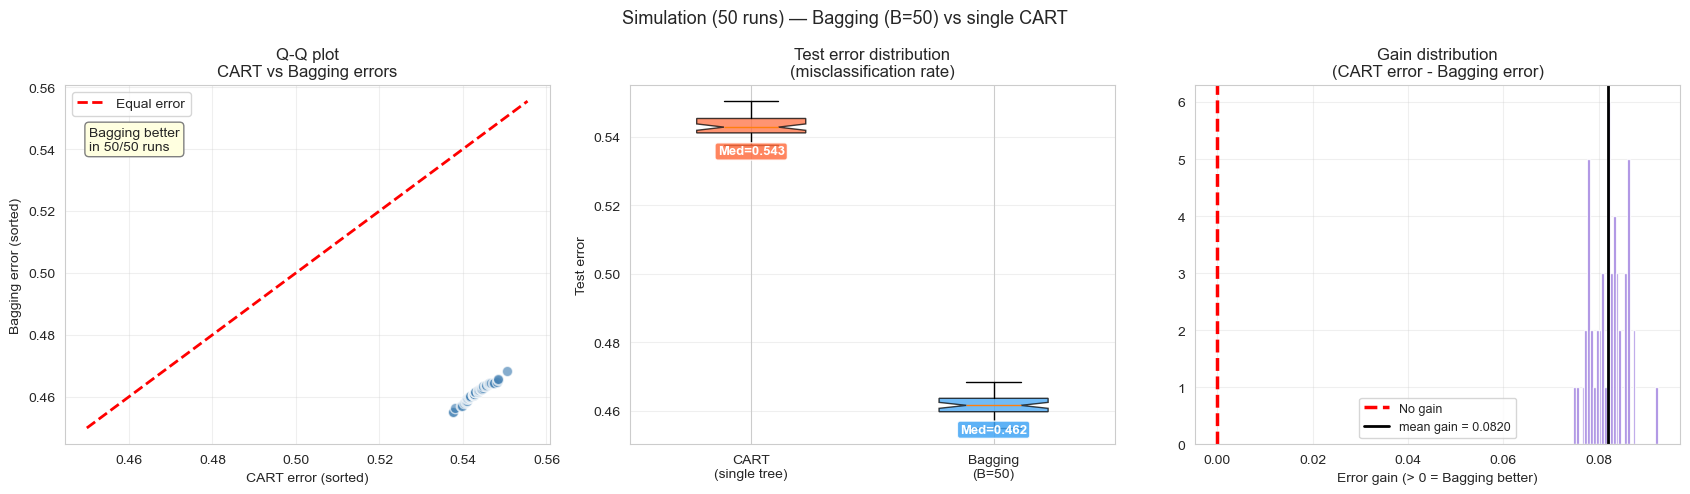

In [38]:
N_SIM = 50
B_SIM = 50
errors_cart, errors_bag = [], []

for sim in range(N_SIM):
    Xtr, Xte, ytr, yte = train_test_split(
        X.values, y, test_size=0.3, random_state=sim, stratify=y
    )
    c = DecisionTreeClassifier(random_state=sim)
    c.fit(Xtr, ytr)
    errors_cart.append(1 - accuracy_score(yte, c.predict(Xte)))

    b = BaggingClassifier(estimator=DecisionTreeClassifier(),
                          n_estimators=B_SIM, bootstrap=True,
                          random_state=sim, n_jobs=-1)
    b.fit(Xtr, ytr)
    errors_bag.append(1 - accuracy_score(yte, b.predict(Xte)))

errors_cart = np.array(errors_cart)
errors_bag  = np.array(errors_bag)

print(f"  CART   : {errors_cart.mean():.4f} +/- {errors_cart.std():.4f}")
print(f"  Bagging: {errors_bag.mean():.4f} +/- {errors_bag.std():.4f}")
print(f"  Bagging < CART in {np.sum(errors_bag < errors_cart)}/{N_SIM} runs")

fig4, axes4 = plt.subplots(1, 3, figsize=(17, 5))
fig4.suptitle(f"Simulation ({N_SIM} runs) — Bagging (B={B_SIM}) vs single CART",
              fontsize=13)

# Q-Q plot
axes4[0].scatter(np.sort(errors_cart), np.sort(errors_bag),
                 color='steelblue', alpha=0.65, s=55, edgecolors='white')
lims = [min(errors_cart.min(), errors_bag.min()) - 0.005,
        max(errors_cart.max(), errors_bag.max()) + 0.005]
axes4[0].plot(lims, lims, 'r--', lw=2, label='Equal error')
axes4[0].set_title("Q-Q plot\nCART vs Bagging errors")
axes4[0].set_xlabel("CART error (sorted)")
axes4[0].set_ylabel("Bagging error (sorted)")
axes4[0].legend()
axes4[0].grid(alpha=0.3)
n_better = np.sum(errors_bag < errors_cart)
axes4[0].annotate(f"Bagging better\nin {n_better}/{N_SIM} runs",
                  xy=(0.05, 0.82), xycoords='axes fraction', fontsize=10,
                  bbox=dict(boxstyle='round', fc='lightyellow', ec='gray'))

# Boxplot
bp4 = axes4[1].boxplot([errors_cart, errors_bag],
                       tick_labels=['CART\n(single tree)', f'Bagging\n(B={B_SIM})'],
                       patch_artist=True, widths=0.45, notch=True)
bp4['boxes'][0].set_facecolor('#FF7043'); bp4['boxes'][0].set_alpha(0.75)
bp4['boxes'][1].set_facecolor('#42A5F5'); bp4['boxes'][1].set_alpha(0.75)
axes4[1].set_title("Test error distribution\n(misclassification rate)")
axes4[1].set_ylabel("Test error")
for i, (errs, col) in enumerate(zip([errors_cart, errors_bag], ['#FF7043', '#42A5F5']), 1):
    axes4[1].text(i, np.median(errs) - 0.008,
                  f'Med={np.median(errs):.3f}', ha='center', fontsize=9.5,
                  fontweight='bold', color='white',
                  bbox=dict(boxstyle='round,pad=0.2', fc=col, alpha=0.85))
axes4[1].grid(axis='y', alpha=0.3)

# Gain distribution
diffs = errors_cart - errors_bag
axes4[2].hist(diffs, bins=30, color='mediumpurple', edgecolor='white', alpha=0.85)
axes4[2].axvline(0,             color='red',    lw=2.5, linestyle='--', label='No gain')
axes4[2].axvline(diffs.mean(),  color='black',  lw=2,   linestyle='-',
                 label=f'mean gain = {diffs.mean():.4f}')
axes4[2].set_title("Gain distribution\n(CART error - Bagging error)")
axes4[2].set_xlabel("Error gain (> 0 = Bagging better)")
axes4[2].legend(fontsize=9)
axes4[2].grid(alpha=0.3)

plt.tight_layout()
save_fig("bagging_02_cart_vs_bagging_simulation")
plt.show()

Over 50 random splits, a single fully grown tree errs 54.3% of the time, against 46.1% for bagging (B = 50); bagging wins in all 50 runs. A fully grown tree has a very high variance; averaging trees fitted on bootstrap samples removes most of it, which is exactly what bagging is designed for.

very long do not recommend re rerunning


═════════════════════════════════════════════════════════════════
  ACCURACY ESTIMATORS — Test / CV / OOB
═════════════════════════════════════════════════════════════════


  Test error (80/20)    : 0.4569
  5-fold CV             : 0.4561 ± 0.0031
  10-fold CV            : 0.4550 ± 0.0044
  OOB error             : 0.4578


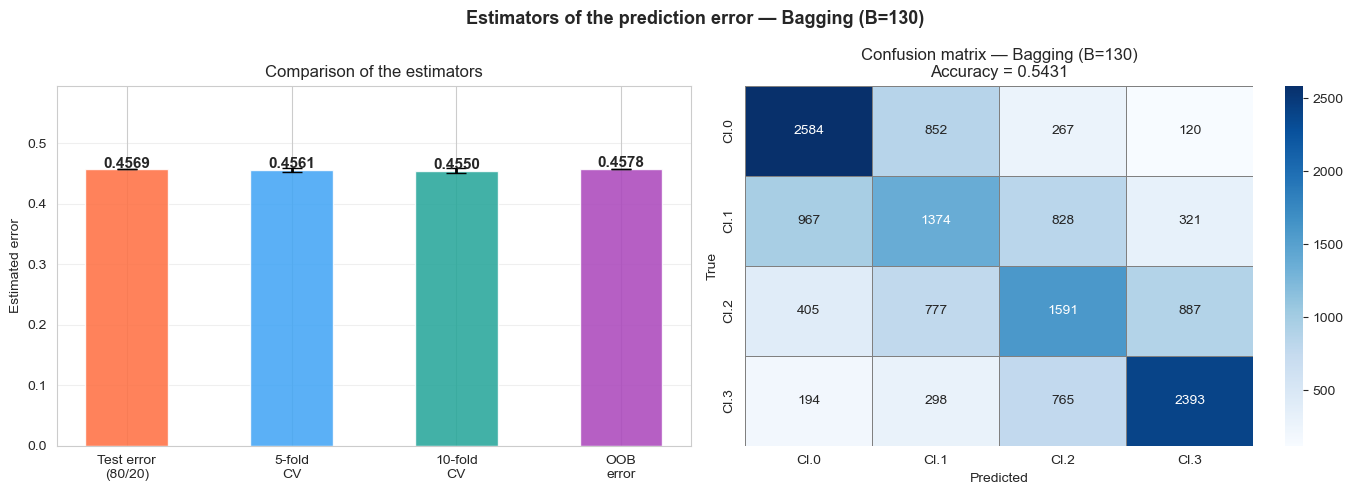

In [39]:
print("\n" + "═"*65)
print("  ACCURACY ESTIMATORS — Test / CV / OOB")
print("═"*65)

B_FINAL = best_B

# Test error
bag_test = BaggingClassifier(estimator=DecisionTreeClassifier(),
                             n_estimators=B_FINAL, bootstrap=True,
                             random_state=42, n_jobs=-1)
bag_test.fit(X_train, y_train)
err_test = 1 - accuracy_score(y_test, bag_test.predict(X_test))

# 5-fold and 10-fold CV
cv_res = {}
for k in [5, 10]:
    bag_cv = BaggingClassifier(estimator=DecisionTreeClassifier(),
                               n_estimators=B_FINAL, bootstrap=True, random_state=42)
    scores = cross_val_score(bag_cv, X.values, y, cv=StratifiedKFold(k, shuffle=True, random_state=42),
                             scoring='accuracy', n_jobs=-1)
    cv_res[k] = 1 - scores

# OOB
bag_oob = BaggingClassifier(estimator=DecisionTreeClassifier(),
                            n_estimators=B_FINAL, bootstrap=True,
                            oob_score=True, random_state=42, n_jobs=-1)
bag_oob.fit(X.values, y)
err_oob = 1 - bag_oob.oob_score_

print(f"  Test error (80/20)    : {err_test:.4f}")
print(f"  5-fold CV             : {cv_res[5].mean():.4f} ± {cv_res[5].std():.4f}")
print(f"  10-fold CV            : {cv_res[10].mean():.4f} ± {cv_res[10].std():.4f}")
print(f"  OOB error             : {err_oob:.4f}")

labels5  = ['Test error\n(80/20)', '5-fold\nCV', '10-fold\nCV', 'OOB\nerror']
means5   = [err_test, cv_res[5].mean(), cv_res[10].mean(), err_oob]
stds5    = [0, cv_res[5].std(), cv_res[10].std(), 0]
colors5  = ['#FF7043', '#42A5F5', '#26A69A', '#AB47BC']

fig5, axes5 = plt.subplots(1, 2, figsize=(14, 5))
fig5.suptitle(f"Estimators of the prediction error — Bagging (B={B_FINAL})",
              fontsize=13, fontweight='bold')

bars5 = axes5[0].bar(labels5, means5, color=colors5, edgecolor='white',
                     width=0.5, alpha=0.87)
axes5[0].errorbar(range(4), means5, yerr=stds5,
                  fmt='none', color='black', capsize=7, lw=2)
for bar, val in zip(bars5, means5):
    axes5[0].text(bar.get_x() + bar.get_width()/2, val + 0.003,
                  f'{val:.4f}', ha='center', fontsize=11, fontweight='bold')
axes5[0].set_ylabel("Estimated error")
axes5[0].set_title("Comparison of the estimators")
axes5[0].set_ylim(0, max(means5) * 1.3)
axes5[0].grid(axis='y', alpha=0.3)

# Confusion matrix of the bagging model
y_pred_final = bag_test.predict(X_test)
cm = confusion_matrix(y_test, y_pred_final)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes5[1],
            xticklabels=CLASS_SHORT, yticklabels=CLASS_SHORT,
            linewidths=0.5, linecolor='gray')
axes5[1].set_title(f"Confusion matrix — Bagging (B={B_FINAL})\n"
                   f"Accuracy = {1-err_test:.4f}")
axes5[1].set_xlabel("Predicted")
axes5[1].set_ylabel("True")

plt.tight_layout()
save_fig("bagging_03_error_estimators")
plt.show()

The four estimates of the bagging error agree within 0.3 point: test 0.457, 5-fold CV 0.456, 10-fold CV 0.455, OOB 0.458. The OOB error is a free and reliable substitute for cross-validation.

Random forest

Grid search to find the best hyperparameters using cross-validation

In [40]:
# hyperparameters to explore
param_grid = {
    # sqrt(p) is the standard choice, log2 is more conservative
    'max_features': ['sqrt', 'log2'], 

    # more trees reduces variance, but gains plateau at some point
    'n_estimators': [100, 300], 

    # deeper trees risk memorising the training data
    'max_depth': [10, 15, 20, 30],

    # minimum samples per leaf, higher values smooth out variance
    'min_samples_leaf': [2, 5, 10]
}

In [41]:
def run_custom_grid_search(X, y, scoring_metric='accuracy'):
    print(f"\n Running Grid Search (metric: {scoring_metric})...")
    
    rf = RandomForestClassifier(random_state=123, n_jobs=-1)
    
    grid_search = GridSearchCV(
        estimator=rf,
        param_grid=param_grid,
        cv=5,                  # 5-Fold Cross Validation
        scoring=scoring_metric,
        return_train_score=True, # to check for overfitting
        n_jobs=-1
    )
    
    grid_search.fit(X, y)
    
    results = pd.DataFrame(grid_search.cv_results_)
    
    cols_interest = [
        'param_max_depth', 'param_max_features', 'param_min_samples_leaf', 'param_n_estimators',
        'mean_test_score', 'std_test_score',  # Validation performance (Variance)
        'mean_train_score'                    # Training performance (Bias)
    ]
    summary = results[cols_interest].copy()
    
    # Rename for readability
    summary.rename(columns={
        'mean_test_score': 'Mean_CV_Score',
        'std_test_score': 'CV_Std (Variance)',
        'mean_train_score': 'Train_Score (Overfit?)'
    }, inplace=True)
    
    # Sort by best validation score
    summary = summary.sort_values(by='Mean_CV_Score', ascending=False)
    
    return grid_search.best_estimator_, summary

Grid search over accuracy and F1-macro

In [42]:
# The grid search takes 15-30 min: its results are cached in results/ and only recomputed when the cache is missing
GRID_CACHE_ACC = RESULTS_DIR / "rf_grid_paris_accuracy.csv"
RUN_GRID_SEARCH = not GRID_CACHE_ACC.exists()
if RUN_GRID_SEARCH:
    # grid search on accuracy
    best_model_acc, res_acc = run_custom_grid_search(X_train, y_train, scoring_metric='accuracy')
    res_acc.to_csv(GRID_CACHE_ACC, index=False)
else:
    res_acc = pd.read_csv(GRID_CACHE_ACC)

print("\n Top 5 configurations (accuracy):")
# check the top 5 to manually pick the best trade-off
print(res_acc.head(5).to_string(index=False))


 Running Grid Search (metric: accuracy)...



 Top 5 configurations (accuracy):
 param_max_depth param_max_features  param_min_samples_leaf  param_n_estimators  Mean_CV_Score  CV_Std (Variance)  Train_Score (Overfit?)
              20               log2                       2                 300       0.558867           0.002240                0.860732
              20               sqrt                       2                 300       0.558867           0.002240                0.860732
              30               log2                       5                 300       0.557003           0.001783                0.746516
              30               sqrt                       5                 300       0.557003           0.001783                0.746516
              20               sqrt                       2                 100       0.556935           0.001232                0.855620


5 folds on the 58,488 training listings: each fit uses about 46.8k listings and is validated on about 11.7k, which is enough for stable estimates (CV standard deviation ≈ 0.001–0.004).

Also running on F1-macro to check if it changes anything — in theory it shouldn't, the classes are balanced by construction.

In [43]:
GRID_CACHE_F1 = RESULTS_DIR / "rf_grid_paris_f1_macro.csv"
RUN_GRID_SEARCH = not GRID_CACHE_F1.exists()
if RUN_GRID_SEARCH:
    # TEST ON F1-MACRO
    best_model_f1, res_f1 = run_custom_grid_search(X_train, y_train, scoring_metric='f1_macro')
    res_f1.to_csv(GRID_CACHE_F1, index=False)
else:
    res_f1 = pd.read_csv(GRID_CACHE_F1)

print("\n TOP 5 CONFIGURATIONS (F1-MACRO):")
print(res_f1.head(5).to_string(index=False))


 Running Grid Search (metric: f1_macro)...



 TOP 5 CONFIGURATIONS (F1-MACRO):
 param_max_depth param_max_features  param_min_samples_leaf  param_n_estimators  Mean_CV_Score  CV_Std (Variance)  Train_Score (Overfit?)
              20               sqrt                       2                 300       0.549990           0.002666                0.860274
              20               log2                       2                 300       0.549990           0.002666                0.860274
              30               log2                       2                 300       0.548241           0.003043                0.925911
              30               sqrt                       2                 300       0.548241           0.003043                0.925911
              30               log2                       2                 100       0.548136           0.004144                0.920610


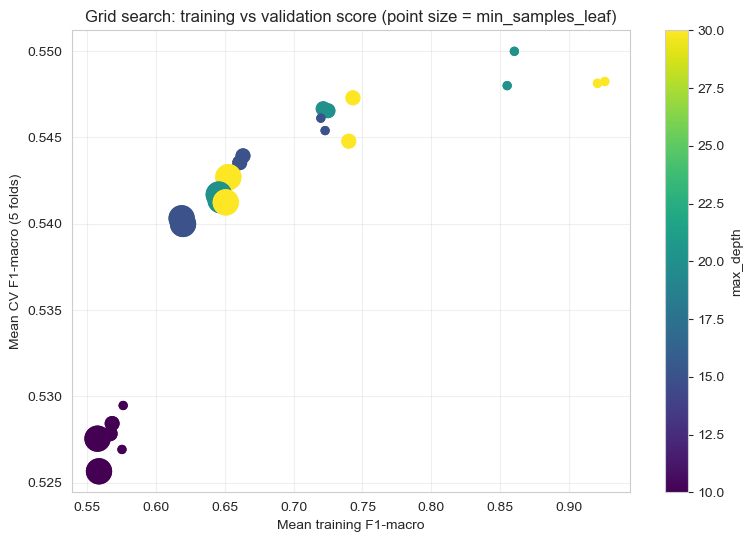

In [44]:
# Bias-variance view of the grid: training score vs cross-validated score for each configuration
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(res_f1['Train_Score (Overfit?)'], res_f1['Mean_CV_Score'],
                c=res_f1['param_max_depth'], s=20 + 3 * res_f1['param_min_samples_leaf'] ** 2, cmap='viridis')
plt.colorbar(sc, label='max_depth')
ax.set_xlabel('Mean training F1-macro')
ax.set_ylabel('Mean CV F1-macro (5 folds)')
ax.set_title('Grid search: training vs validation score (point size = min_samples_leaf)')
ax.grid(alpha=0.3)
save_fig("rf_01_grid_bias_variance")
plt.show()

Training scores range from 0.56 to 0.93, while CV scores stay between 0.525 and 0.550. Deeper trees with smaller leaves fit the training data much better (each tree overfits). They still slightly improve the validation score, because averaging 300 decorrelated trees removes most of their variance. The training score is therefore a poor guide here; only the validation score is used for the choice.

Both metrics select the same configuration: `max_depth=20`, `min_samples_leaf=2`, 300 trees (CV accuracy 0.559, CV F1-macro 0.550). `sqrt` and `log2` tie exactly because, with 24 features, both draw 4 features per split, so half of the grid repeats the same fits. We keep this configuration.

In [45]:
# Configuration kept: the best one by F1-macro (cached grid above)
best_cfg = res_f1.iloc[0]
opti_max_depth = int(best_cfg['param_max_depth'])
opti_param_max_features = best_cfg['param_max_features']
opti_param_min_samples_leaf = int(best_cfg['param_min_samples_leaf'])
opti_param_n_estimators = int(best_cfg['param_n_estimators'])
print(best_cfg.to_string())

param_max_depth                 20
param_max_features            sqrt
param_min_samples_leaf           2
param_n_estimators             300
Mean_CV_Score              0.54999
CV_Std (Variance)         0.002666
Train_Score (Overfit?)    0.860274


In [46]:
rf_opti = RandomForestClassifier(
    n_estimators=opti_param_n_estimators,
    max_depth=opti_max_depth,
    min_samples_leaf=opti_param_min_samples_leaf,
    max_features=opti_param_max_features,
    random_state=123,
    n_jobs=-2       # leave one cpu core free
)

In [47]:
rf_opti.fit(X_train, y_train)

RandomForestClassifier(max_depth=20, min_samples_leaf=2, n_estimators=300,
                       n_jobs=-2, random_state=123)

Results of the optimal model on the test set

In [48]:
y_pred = rf_opti.predict(X_test)
# Scores
acc = accuracy_score(y_test, y_pred)
f1_macro = classification_report(y_test, y_pred, output_dict=True)['macro avg']['f1-score']
print(f"\n FINAL ACCURACY: {acc:.2%}")
print(f" F1-MACRO: {f1_macro:.2%}")


 FINAL ACCURACY: 56.06%
 F1-MACRO: 55.12%


In [49]:
target_names = ['Budget (0)', 'Standard (1)', 'Premium (2)', 'Luxury (3)']
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred, target_names=target_names))


--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

  Budget (0)       0.62      0.72      0.66      3823
Standard (1)       0.44      0.39      0.41      3490
 Premium (2)       0.49      0.42      0.45      3660
  Luxury (3)       0.66      0.69      0.67      3650

    accuracy                           0.56     14623
   macro avg       0.55      0.56      0.55     14623
weighted avg       0.55      0.56      0.55     14623



The OOB score is the forest's internal estimate of its own performance: each tree is evaluated on the samples it never saw during training. If it's close to the test score, that's a good sign

In [50]:
# same params as rf_opti, just with oob_score=True added
rf_oob = RandomForestClassifier(
    n_estimators=opti_param_n_estimators,
    max_depth=opti_max_depth,
    min_samples_leaf=opti_param_min_samples_leaf,
    max_features=opti_param_max_features,
    oob_score=True,
    random_state=123
)

rf_oob.fit(X_train, y_train)

oob_acc = rf_oob.oob_score_
test_acc = accuracy_score(y_test, rf_oob.predict(X_test))

print(f" OOB (internal estimate) : {oob_acc:.4f}")
print(f" Test score (real validation) : {test_acc:.4f}")

if abs(oob_acc - test_acc) < 0.02:
    print("Both scores are very close — the model generalises well.")

 OOB (internal estimate) : 0.5605
 Test score (real validation) : 0.5606
Both scores are very close — the model generalises well.


The OOB score (0.5605) is almost equal to the test accuracy (0.5606). The result doesn't depend on a lucky train/test split.

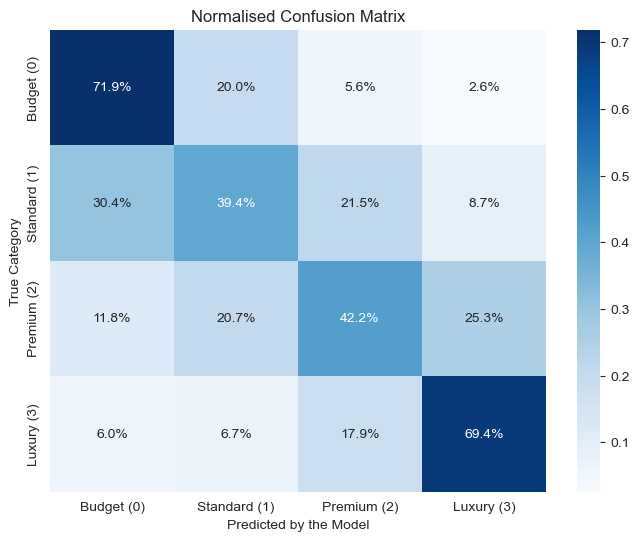

Exact class: 56.1% | off by one class: 33.6% | off by two: 8.2% | Budget <-> Luxury: 2.2%


In [51]:
#Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)

# Normalise to get percentages
cmn = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

sns.heatmap(cmn, annot=True, fmt='.1%', cmap='Blues', 
            xticklabels=target_names, yticklabels=target_names)
plt.ylabel('True Category')
plt.xlabel('Predicted by the Model')
plt.title('Normalised Confusion Matrix')
save_fig("rf_02_confusion_matrix_normalised")
plt.show()

# Distance between true and predicted class
off_by = np.abs(np.asarray(y_test) - y_pred)
print(f"Exact class: {np.mean(off_by == 0):.1%} | off by one class: {np.mean(off_by == 1):.1%} | "
      f"off by two: {np.mean(off_by == 2):.1%} | Budget <-> Luxury: {np.mean(off_by == 3):.1%}")

### Reading the confusion matrix

The model does well at the extremes: **Budget** is recognised in 72% of cases and **Luxury** in 69%. These two categories have fairly distinct profiles.

It struggles with **Standard** (39%) and **Premium** (42%). The difference between neighbouring classes probably lies in information the features do not contain — surface area, decoration, light, photos. Photo features could test this hypothesis.

The errors are mostly near misses:
- 56.1% exact class;
- 33.6% one class off;
- 8.2% two classes off;
- 2.2% Budget ↔ Luxury.

INTERPRETATION (FEATURE IMPORTANCE)

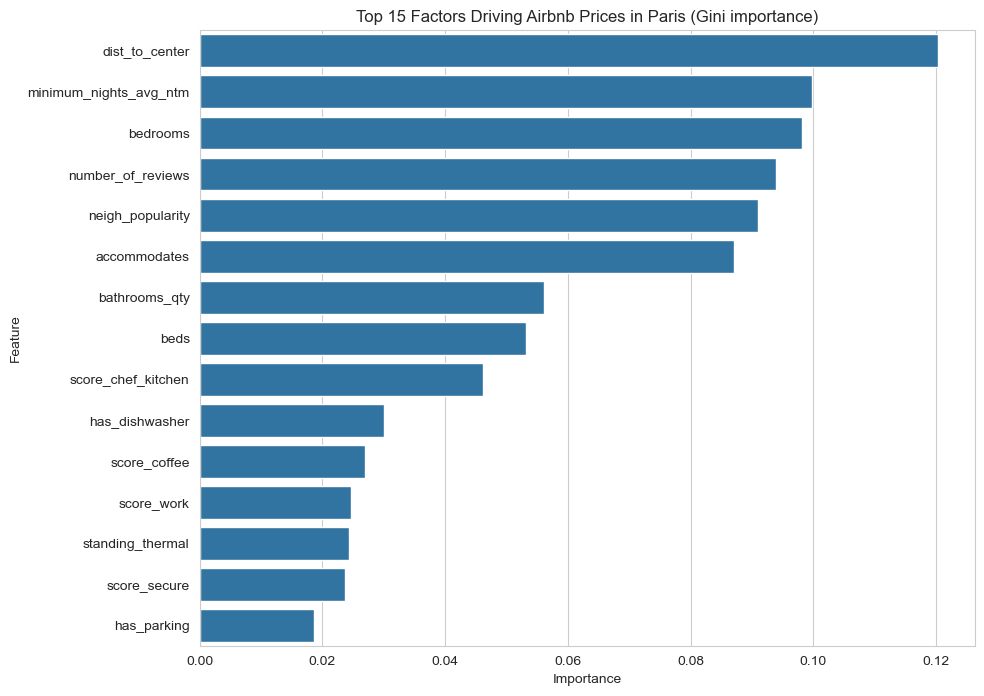

In [52]:
importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_opti.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importances.head(15))
plt.title('Top 15 Factors Driving Airbnb Prices in Paris (Gini importance)')
save_fig("rf_03_gini_importance")
plt.show()

Feature importance measures each variable's cumulative contribution to reducing Gini impurity across all trees. The more effectively a variable separates classes, the higher its score.

Two caveats:
- it is computed on the training data;
- it favours continuous features with many possible split points (distance, review counts, minimum nights) over binary ones.

The permutation importance below, measured on the test set, corrects both.

               Feature  Importance    Std
          accommodates      0.0447 0.0029
              bedrooms      0.0421 0.0015
minimum_nights_avg_ntm      0.0374 0.0020
     number_of_reviews      0.0359 0.0014
      neigh_popularity      0.0345 0.0016
        dist_to_center      0.0286 0.0009
        has_dishwasher      0.0185 0.0014
          score_secure      0.0102 0.0008
    score_chef_kitchen      0.0084 0.0010
   has_washing_machine      0.0061 0.0006
         bathrooms_qty      0.0061 0.0006
          has_elevator      0.0056 0.0011
    rt_Entire home/apt      0.0047 0.0008
          score_coffee      0.0042 0.0023
       rt_Private room      0.0041 0.0006


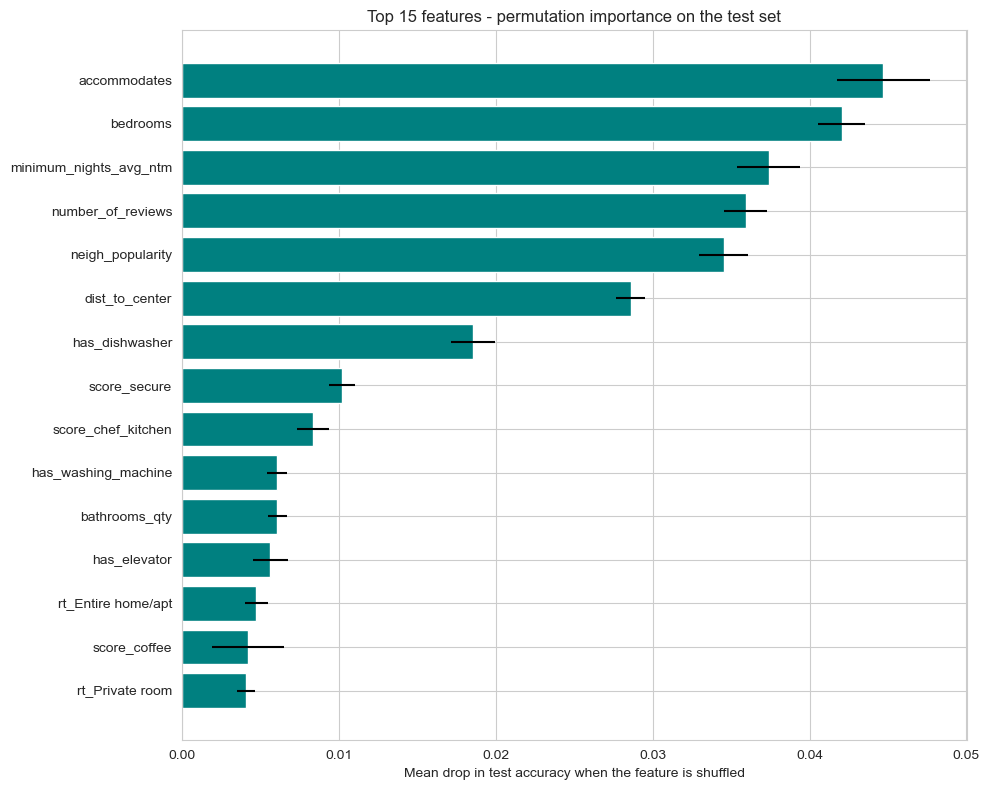

In [53]:
# Permutation importance on the test set: drop in accuracy when one feature is shuffled.
# Unlike the Gini importance, it is measured on unseen data and is not biased towards continuous features.
perm = permutation_importance(rf_opti, X_test, y_test, n_repeats=5, random_state=42, scoring='accuracy')
perm_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': perm.importances_mean,
    'Std': perm.importances_std
}).sort_values(by='Importance', ascending=False)
print(perm_df.head(15).round(4).to_string(index=False))

plt.figure(figsize=(10, 8))
top_perm = perm_df.head(15)
plt.barh(top_perm['Feature'][::-1], top_perm['Importance'][::-1], xerr=top_perm['Std'][::-1], color='teal')
plt.title('Top 15 features - permutation importance on the test set')
plt.xlabel('Mean drop in test accuracy when the feature is shuffled')
plt.tight_layout()
save_fig("rf_04_permutation_importance")
plt.show()

### What drives price in Paris

The two importance measures agree on the main families but not on the order:

| Rank | Gini importance (train) | Permutation importance (test) |
|---|---|---|
| 1 | dist_to_center | accommodates |
| 2 | minimum_nights_avg_ntm | bedrooms |
| 3 | bedrooms | minimum_nights_avg_ntm |
| 4 | number_of_reviews | number_of_reviews |
| 5 | neigh_popularity | neigh_popularity |
| 6 | accommodates | dist_to_center |

1. **Size** (accommodates, bedrooms) is the main driver once the bias of the Gini importance is removed. Shuffling either costs about 4–4.5 points of accuracy.
2. **Host behaviour** (minimum stay, number of reviews) ranks high in both measures. Listings without reviews are more expensive (see the CART section), and long minimum stays point to a different, more professional type of offer. These are associations, not causes.
3. **Location** (distance to the centre — Hôtel de Ville — and neighbourhood popularity) matters, but less than the Gini ranking suggests: the Gini importance favours this continuous feature.
4. **Room type** has a low permutation importance (≈ 0.005). Its information is largely shared with correlated features (capacity, bathrooms, dishwasher), and permutation importance only measures what a feature adds on top of the others.

### Performance summary

**56.1% accuracy and 0.551 F1-macro** on 4 balanced classes, against 25% by chance: the model has clearly learned something meaningful.

F1-macro is close to accuracy, so no class is sacrificed. The extreme classes (Budget and Luxury) are predicted more reliably; the middle ones are harder to tell apart without richer data.

Overall the model is usable for filtering price ranges, even if you shouldn't expect pinpoint precision between Standard and Premium.

### Model comparison with bootstrap confidence intervals

All models are now scored on the same test set (14,623 listings). To check that the differences between them are larger than the sampling noise of the test set, we resample the test rows with replacement 1,000 times. Every model is scored on the same resampled rows (a paired bootstrap), which gives a 95% confidence interval for each score and for the gap between the random forest and LDA.

                 Accuracy  F1-macro  F1 CI95 low  F1 CI95 high
LDA                0.4811    0.4723       0.4646        0.4805
Pruned CART        0.5223    0.5160       0.5075        0.5238
Bagging (B=130)    0.5431    0.5374       0.5295        0.5450
Random forest      0.5606    0.5512       0.5432        0.5594

RF - LDA F1-macro gap: +0.0789, CI95 [+0.0709, +0.0864]


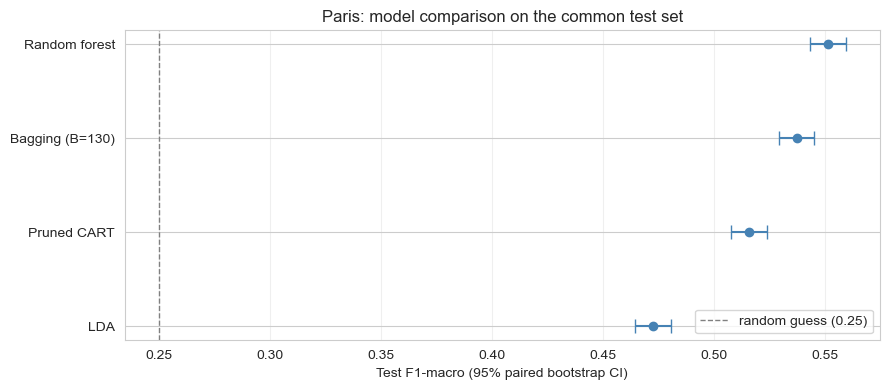

In [54]:
# Paired bootstrap on the common test set: every model is scored on the same resampled rows
lda_cmp = LinearDiscriminantAnalysis().fit(X_train, y_train)
cart_cmp = DecisionTreeClassifier(ccp_alpha=optimal_alpha, random_state=42).fit(X_train, y_train)
preds = {
    'LDA': lda_cmp.predict(X_test),
    'Pruned CART': cart_cmp.predict(X_test),
    f'Bagging (B={B_FINAL})': bag_test.predict(X_test),
    'Random forest': y_pred,
}

rng = np.random.default_rng(42)
N_BOOT_METRICS = 1000
boot_f1 = {m: [] for m in preds}
for _ in range(N_BOOT_METRICS):
    idx = rng.integers(0, len(y_test), len(y_test))
    for m, p in preds.items():
        boot_f1[m].append(f1_score(y_test[idx], p[idx], average='macro'))

summary_models = pd.DataFrame({
    'Accuracy': {m: accuracy_score(y_test, p) for m, p in preds.items()},
    'F1-macro': {m: f1_score(y_test, p, average='macro') for m, p in preds.items()},
    'F1 CI95 low': {m: np.percentile(v, 2.5) for m, v in boot_f1.items()},
    'F1 CI95 high': {m: np.percentile(v, 97.5) for m, v in boot_f1.items()},
})
print(summary_models.round(4).to_string())
summary_models.to_csv(RESULTS_DIR / "paris_model_comparison.csv")

gap = np.array(boot_f1['Random forest']) - np.array(boot_f1['LDA'])
print(f"\nRF - LDA F1-macro gap: {gap.mean():+.4f}, CI95 [{np.percentile(gap, 2.5):+.4f}, {np.percentile(gap, 97.5):+.4f}]")

fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(summary_models['F1-macro'], range(len(preds)),
            xerr=[summary_models['F1-macro'] - summary_models['F1 CI95 low'],
                  summary_models['F1 CI95 high'] - summary_models['F1-macro']],
            fmt='o', capsize=5, color='steelblue')
ax.set_yticks(range(len(preds)))
ax.set_yticklabels(preds.keys())
ax.axvline(0.25, color='grey', linestyle='--', lw=1, label='random guess (0.25)')
ax.set_xlabel('Test F1-macro (95% paired bootstrap CI)')
ax.set_title('Paris: model comparison on the common test set')
ax.legend()
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
save_fig("comparison_01_models_bootstrap_ci")
plt.show()

**Model ranking on the common test set** (F1-macro, 95% paired-bootstrap interval):
- random forest 0.551 [0.543, 0.559];
- bagging 0.537 [0.530, 0.545];
- pruned CART 0.516 [0.508, 0.524];
- LDA 0.472 [0.465, 0.481].

The intervals do not overlap, and the paired gap between the random forest and LDA is +7.9 points [+7.1, +8.6]. Each step adds 1.4 to 4.4 points:
- non-linear rules (CART vs LDA);
- averaging (bagging vs CART);
- random feature subsets (random forest vs bagging).

The ceiling stays around 55%: the next gains will come from more informative features rather than from a different algorithm (see `docs/EXTENSIONS.md`).